<center><h2> Supplementary Information </h2></center>

Figures S1–S14 and Tables S1–S3, numbered as in the Supporting Information. Figures are saved to `figs/FigureSN.png`.

**____________________________________________________________________________________________________________________________**


## Figure S1
### Thickness-weighted mean O<sub>2</sub> trends (0–1000 m, 2004–2020) from GOBAI-O<sub>2</sub> v2.3 and ML4O<sub>2</sub>

#### Relevant inputs: data/CONTENT_DIC_v2-3.nc, data/o2_NN_ship+Argo_ensmean.nc

Using symmetric color range ±0.618


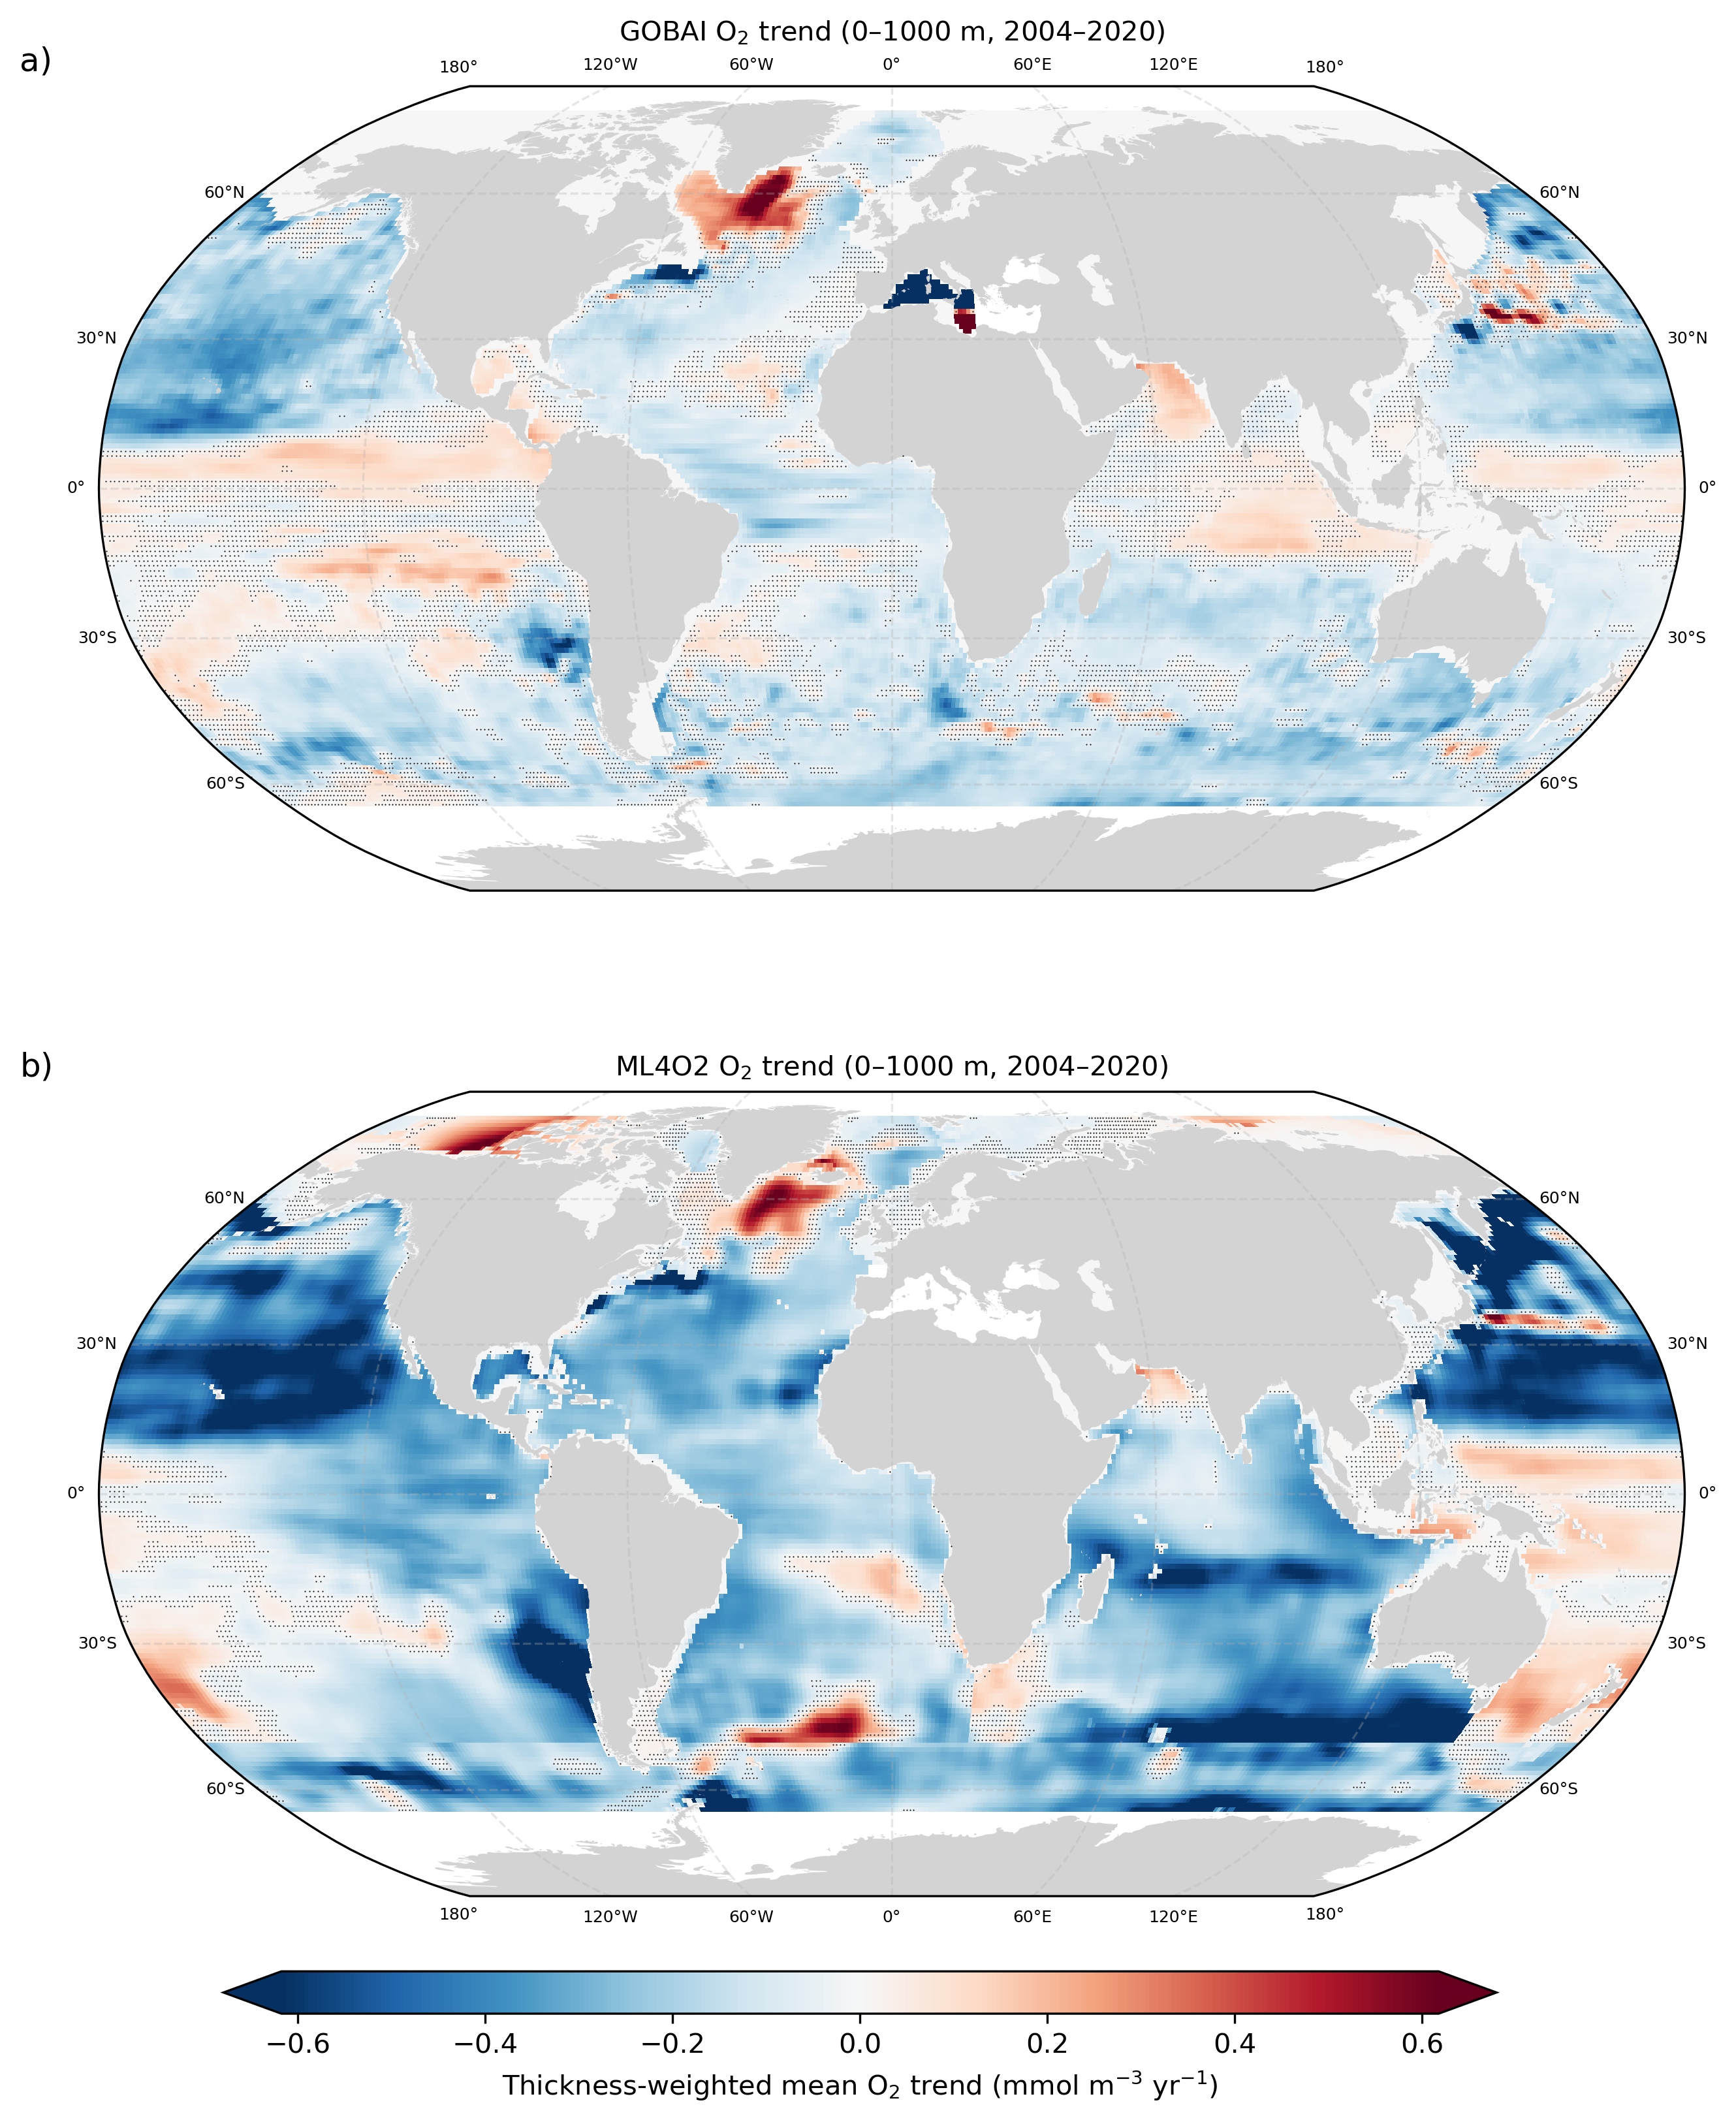

Saved: figs/FigureS1.png


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

from matplotlib.colors import TwoSlopeNorm
from scipy.stats import t as student_t

# ============================================================
# SETTINGS
# ============================================================
TIME0 = "2004-01-01"
TIME1 = "2020-12-31"
ZMIN  = 0
ZMAX  = 1000

PLOT_WHAT = "mean"   # "mean" recommended
PCTL = 98            # robust symmetric color scaling percentile

PVAL_ALPHA = 0.05
ZERO_TREND_TOL = 1e-12

STIPPLE_SIZE = 1.0
STIPPLE_COLOR = "black"

OUTPATH = "figs/FigureS1.png"

# ============================================================
# HELPERS
# ============================================================
def mask_mediterranean(lat, lon):
    return (lat >= 30) & (lat <= 46) & (lon >= -6) & (lon <= 37)

def slope_and_se_1d(y, tvec):
    """
    Regression of y against tvec.
    Returns slope, standard error of slope, p-value.
    """
    y = np.asarray(y, dtype=float)
    tvec = np.asarray(tvec, dtype=float)

    m = np.isfinite(y) & np.isfinite(tvec)
    n = int(m.sum())
    if n < 3:
        return np.nan, np.nan, np.nan

    yy = y[m]
    tt = tvec[m]

    tbar = tt.mean()
    ybar = yy.mean()

    tt_c = tt - tbar
    yy_c = yy - ybar

    sxx = np.sum(tt_c**2)
    if sxx <= 0 or not np.isfinite(sxx):
        return np.nan, np.nan, np.nan

    slope = np.sum(tt_c * yy_c) / sxx
    intercept = ybar - slope * tbar

    yhat = intercept + slope * tt
    resid = yy - yhat

    df = n - 2
    if df <= 0:
        return slope, np.nan, np.nan

    s2 = np.sum(resid**2) / df
    se_slope = np.sqrt(s2 / sxx)

    if not np.isfinite(se_slope) or se_slope == 0:
        return slope, se_slope, np.nan

    tstat = slope / se_slope
    pval = 2.0 * student_t.sf(np.abs(tstat), df)

    return slope, se_slope, pval

# ============================================================
# LOAD DATA
# ============================================================
ds  = xr.load_dataset("data/CONTENT_DIC_v2-3.nc")          # GOBAI-like
ito = xr.load_dataset("data/o2_NN_ship+Argo_ensmean.nc")   # ML4O2

# ============================================================
# GOBAI: trend field over 0-1000 dbar
# ============================================================
g = ds.sel(time=slice(TIME0, TIME1)).sel(pres=slice(ZMIN, ZMAX))

t_year_g = ((g["time"] - g["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
g = g.assign_coords(t_year=("time", t_year_g.data))

fit_g = g["oxy"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_g = fit_g["polyfit_coefficients"].sel(degree=1)  # per year at each depth

dp = g["pres"].diff("pres").reindex(pres=g["pres"], method=None).fillna(0)
dp = dp.broadcast_like(o2_trend_g)

o2_meantrend_gobai = ((o2_trend_g * dp).sum("pres", skipna=True) / dp.sum("pres")).rename("O2_meantrend_gobai")

# thickness-weighted mean O2 time series for significance
o2bar_g_t = (g["oxy"] * dp).sum("pres", skipna=True) / dp.sum("pres")
tg = g["t_year"].values.astype(float)

_, se_g, pval_g = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_g_t,
    xr.DataArray(tg, dims=("time",), coords={"time": o2bar_g_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# ML4O2: trend field over 0-1000 m
# ============================================================
i = ito.sel(time=slice(TIME0, TIME1)).sel(depth=slice(ZMIN, ZMAX))

t_year_i = ((i["time"] - i["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
i = i.assign_coords(t_year=("time", t_year_i.data))

fit_i = i["o2"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_i = fit_i["polyfit_coefficients"].sel(degree=1)

dz = i["depth"].diff("depth").reindex(depth=i["depth"], method=None).fillna(0)
dz = dz.broadcast_like(o2_trend_i)

o2_meantrend_ito = ((o2_trend_i * dz).sum("depth", skipna=True) / dz.sum("depth")).rename("O2_meantrend_ito")

# thickness-weighted mean O2 time series for significance
o2bar_i_t = (i["o2"] * dz).sum("depth", skipna=True) / dz.sum("depth")
ti = i["t_year"].values.astype(float)

_, se_i, pval_i = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_i_t,
    xr.DataArray(ti, dims=("time",), coords={"time": o2bar_i_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# PREPARE PLOTTING FIELDS
# ============================================================
gobai_2d = o2_meantrend_gobai.transpose("lat", "lon")
ito_2d   = o2_meantrend_ito.transpose("lat", "lon")

lat_g = gobai_2d["lat"].values
ito_2d = ito_2d.sel(lat=slice(lat_g.min(), lat_g.max()))

pval_g = pval_g.transpose("lat", "lon")
pval_i = pval_i.transpose("lat", "lon").sel(lat=slice(lat_g.min(), lat_g.max()))

# Mediterranean mask
lat2d_g, lon2d_g = xr.broadcast(gobai_2d["lat"], gobai_2d["lon"])
lat2d_i, lon2d_i = xr.broadcast(ito_2d["lat"], ito_2d["lon"])

med_g = mask_mediterranean(lat2d_g, lon2d_g)
med_i = mask_mediterranean(lat2d_i, lon2d_i)

gobai_2d = gobai_2d.where(~med_g)
ito_2d   = ito_2d.where(~med_i)

pval_g = pval_g.where(~med_g).where(np.isfinite(gobai_2d))
pval_i = pval_i.where(~med_i).where(np.isfinite(ito_2d))

# non-significant stippling masks, excluding zero-trend cells
nonsig_g = (pval_g >= PVAL_ALPHA) & (np.abs(gobai_2d) > ZERO_TREND_TOL)
nonsig_i = (pval_i >= PVAL_ALPHA) & (np.abs(ito_2d) > ZERO_TREND_TOL)

# Convert to numpy
gobai_map = gobai_2d.values
ito_map   = ito_2d.values

# shared robust symmetric color scale
allvals = np.concatenate([gobai_map.ravel(), ito_map.ravel()])
allvals = allvals[np.isfinite(allvals)]
v = np.nanpercentile(np.abs(allvals), PCTL)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v)

print(f"Using symmetric color range ±{v:.3f}")

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(13, 12), dpi=300)

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)

# ----------------------------
# Panel a: GOBAI
# ----------------------------
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.Robinson())
ax1.set_global()
ax1.add_feature(land)
ax1.text(-0.05, 1.05, "a)", transform=ax1.transAxes, fontsize=12, va="top")

gl1 = ax1.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl1.top_labels = True
gl1.bottom_labels = False
gl1.left_labels = True
gl1.right_labels = True
gl1.xformatter = cticker.LongitudeFormatter()
gl1.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl1.xlabel_artists + gl1.ylabel_artists:
    lbl.set_fontsize(6)

im1 = ax1.pcolormesh(
    lon2d_g.values, lat2d_g.values, gobai_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax1.scatter(
    lon2d_g.values[nonsig_g.values],
    lat2d_g.values[nonsig_g.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax1.set_title(
    f"GOBAI O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# ----------------------------
# Panel b: ML4O2
# ----------------------------
ax2 = fig.add_subplot(2, 1, 2, projection=ccrs.Robinson())
ax2.set_global()
ax2.add_feature(land)
ax2.text(-0.05, 1.05, "b)", transform=ax2.transAxes, fontsize=12, va="top")

gl2 = ax2.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl2.top_labels = False
gl2.bottom_labels = True
gl2.left_labels = True
gl2.right_labels = True
gl2.xformatter = cticker.LongitudeFormatter()
gl2.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl2.xlabel_artists + gl2.ylabel_artists:
    lbl.set_fontsize(6)

im2 = ax2.pcolormesh(
    lon2d_i.values, lat2d_i.values, ito_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax2.scatter(
    lon2d_i.values[nonsig_i.values],
    lat2d_i.values[nonsig_i.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax2.set_title(
    f"ML4O2 O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# Shared colorbar
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cbar = fig.colorbar(im1, cax=cax, orientation="horizontal", extend="both")
cbar.set_label(r"Thickness-weighted mean O$_2$ trend (mmol m$^{-3}$ yr$^{-1}$)")

plt.subplots_adjust(hspace=0.25)
fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)

**____________________________________________________________________________________________________________________________**


## Figure S2
### Grid points where the sign of the O<sub>2</sub> trend differs between GOBAI-O<sub>2</sub> and ML4O<sub>2</sub>

#### Uses the trends computed for Fig. S1 (run Fig. S1 first)

Valid pixels: 49028
Sign disagreement pixels: 7405
Fraction disagreement: 15.10%
Red pixels (disagree + GOBAI significant): 3875 (52.33%)
Black pixels (disagree + GOBAI not significant): 3530 (47.67%)


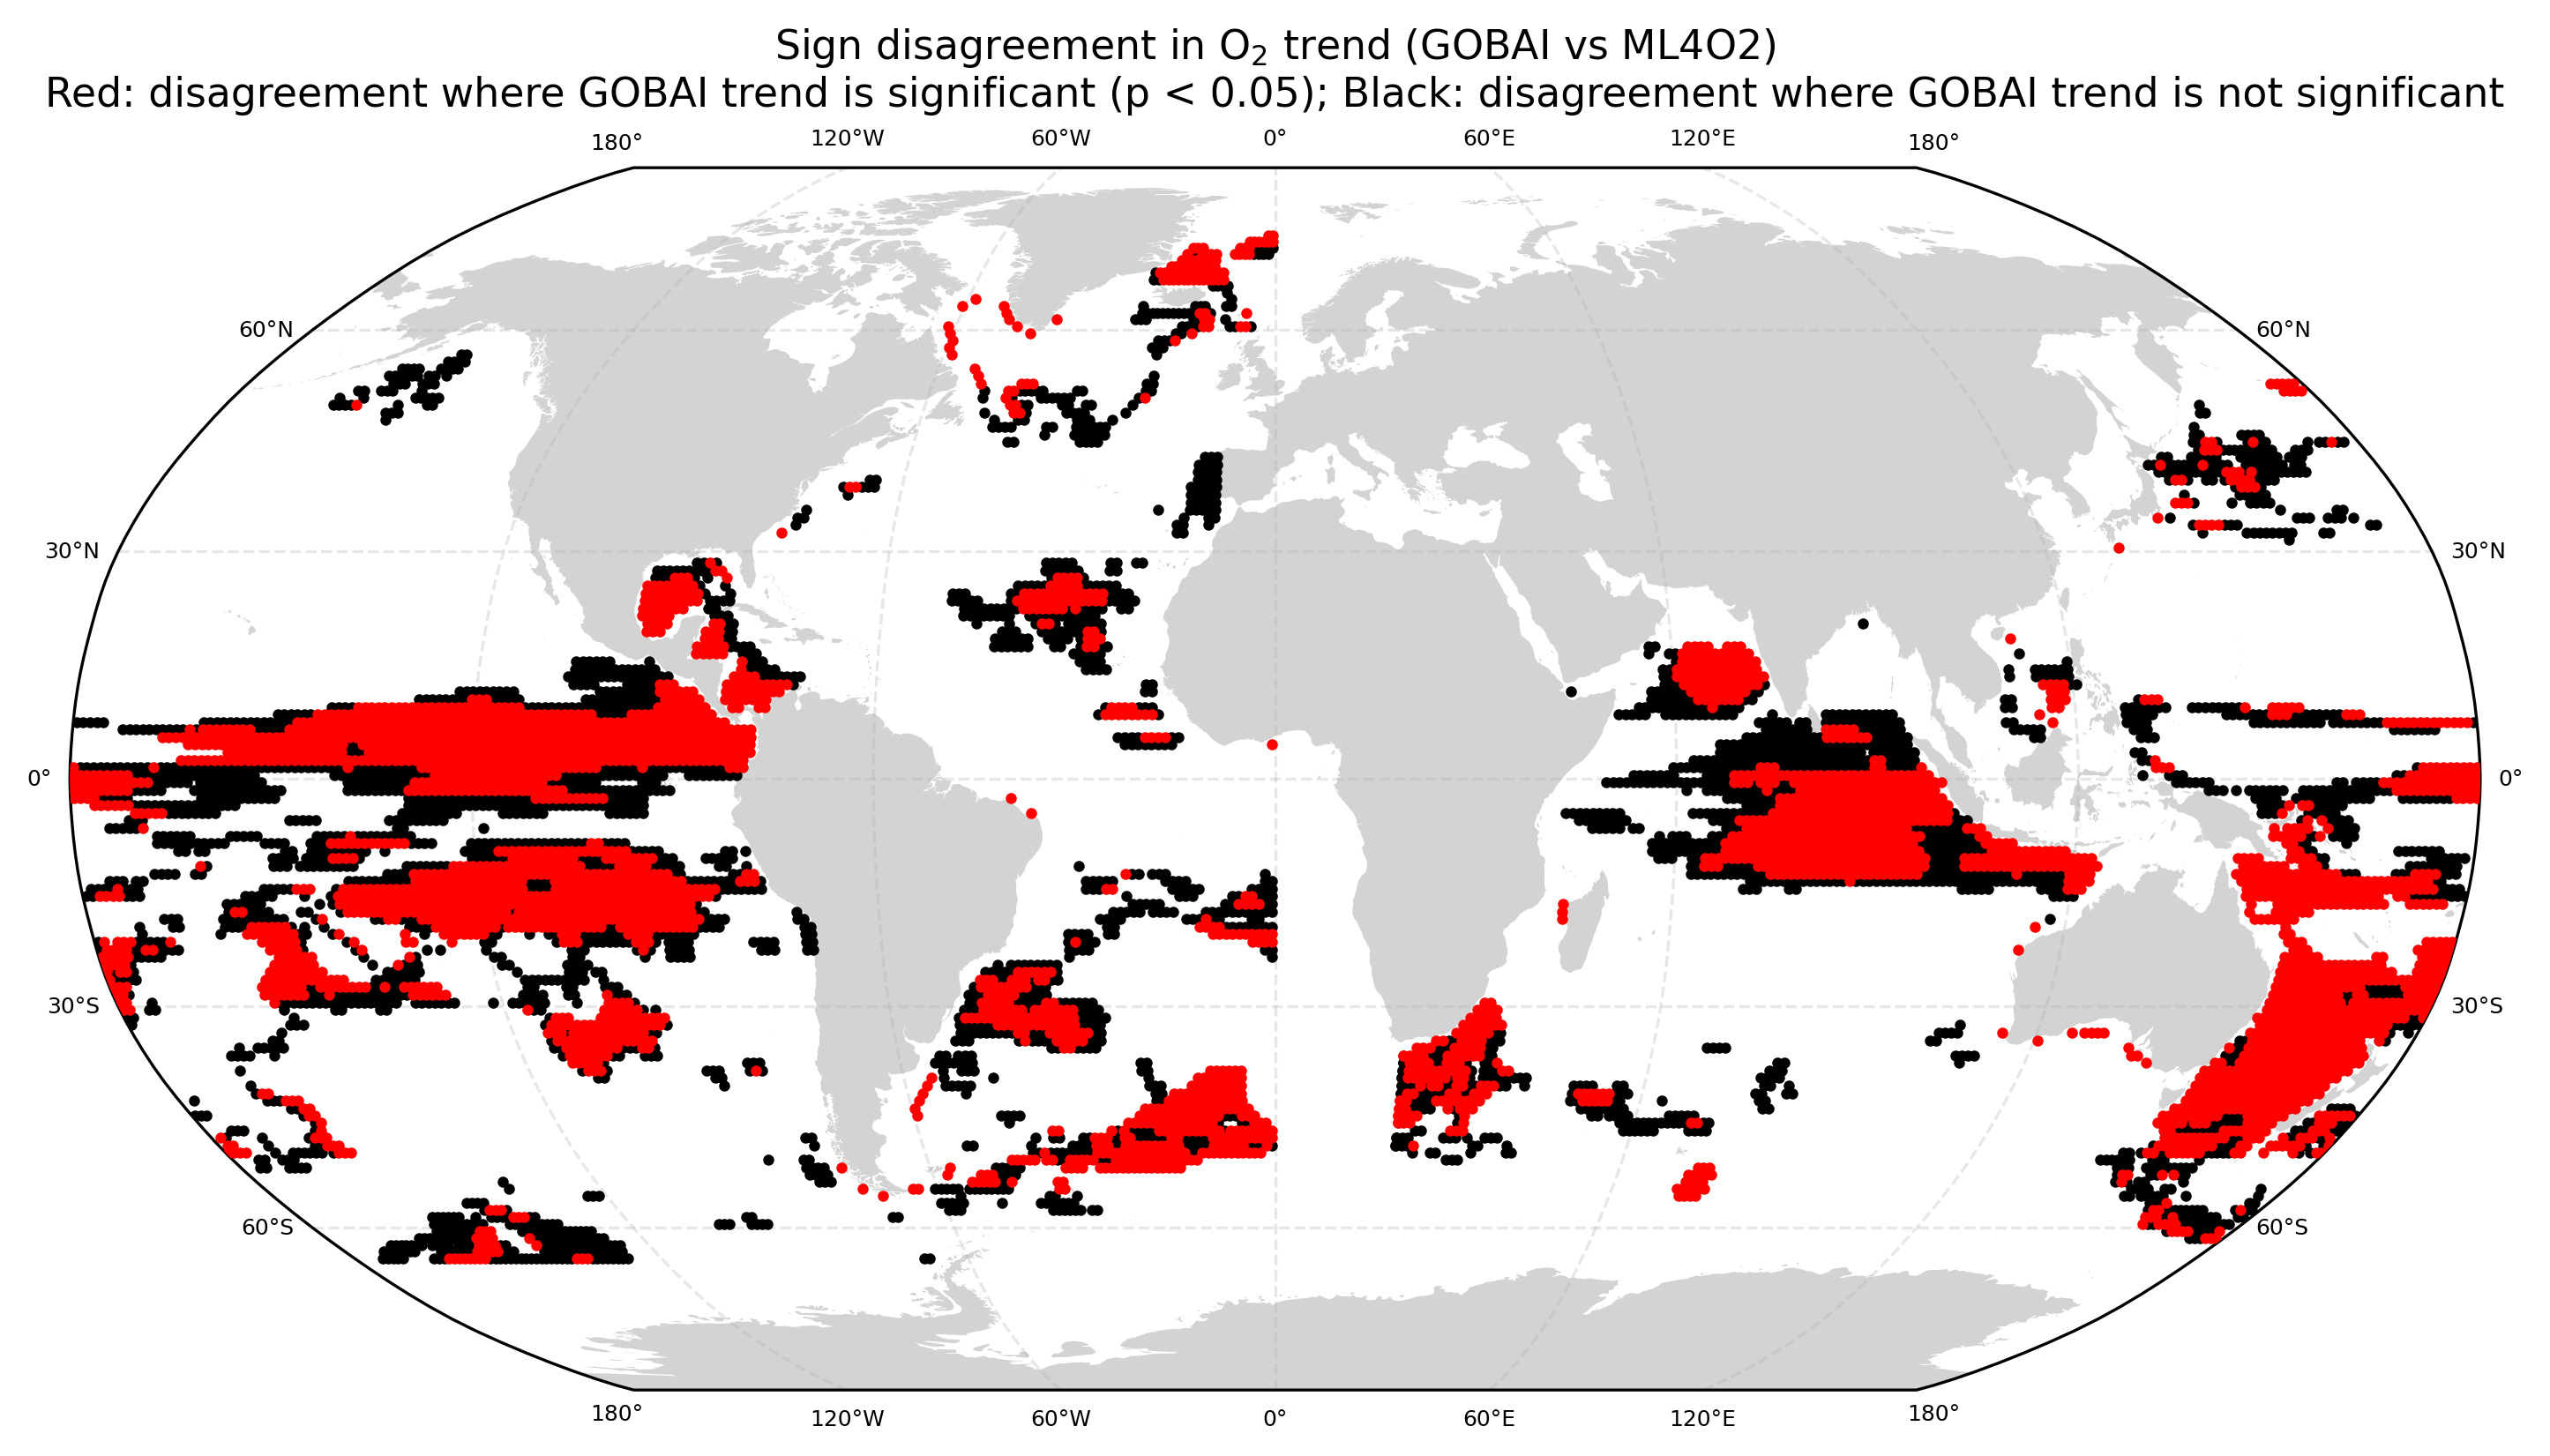

Saved: figs/FigureS2.png


In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point

# ============================================================
# SETTINGS
# ============================================================
DOTSIZE = 4
OUTPATH = "figs/FigureS2.png"

# ============================================================
# REQUIRED INPUTS ALREADY IN MEMORY
# ------------------------------------------------------------
# o2_meantrend_gobai : GOBAI thickness-weighted mean O2 trend
# o2_meantrend_ito   : ML4O2 thickness-weighted mean O2 trend
# pval_g             : GOBAI p-value field for local O2 trend
# mask_mediterranean : function(lat, lon) -> boolean mask
# ============================================================

# ============================================================
# PUT ML4O2 ON SAME LONGITUDE CONVENTION AS GOBAI
# GOBAI: 0–360
# ML4O2: shift from -180–180 to 0–360
# ============================================================
o2_meantrend_ito_shifted = o2_meantrend_ito.assign_coords(
    lon=((o2_meantrend_ito["lon"] + 360) % 360)
).sortby("lon")

# ============================================================
# INTERPOLATE ML4O2 ONTO GOBAI GRID
# ============================================================
ito_on_gobai = o2_meantrend_ito_shifted.interp(
    lat=o2_meantrend_gobai["lat"],
    lon=o2_meantrend_gobai["lon"],
    method="linear"
)

# ============================================================
# MATCH DIMENSIONS
# ============================================================
gtrend = o2_meantrend_gobai.transpose("lat", "lon")
itrend = ito_on_gobai.transpose("lat", "lon")
pval_g = pval_g.transpose("lat", "lon")

# ============================================================
# APPLY MEDITERRANEAN MASK
# ============================================================
lat2d, lon2d = xr.broadcast(gtrend["lat"], gtrend["lon"])
med = mask_mediterranean(lat2d, lon2d)

gtrend = gtrend.where(~med)
itrend = itrend.where(~med)
pval_g = pval_g.where(~med)

# ============================================================
# VALID PIXELS
# ============================================================
valid = np.isfinite(gtrend) & np.isfinite(itrend)

# Opposite sign only
sign_disagree = ((np.sign(gtrend) * np.sign(itrend)) < 0) & valid

# GOBAI significance
gobai_sig = (pval_g < 0.05) & valid

# ------------------------------------------------------------
# Final plotting masks
# black = disagreement where GOBAI is NOT significant
# red   = disagreement where GOBAI IS significant
# ------------------------------------------------------------
mask_red = sign_disagree & gobai_sig
mask_black = sign_disagree & (~gobai_sig)

# ============================================================
# DIAGNOSTICS
# ============================================================
n_valid = int(valid.sum())
n_disagree = int(sign_disagree.sum())
n_red = int(mask_red.sum())
n_black = int(mask_black.sum())

print(f"Valid pixels: {n_valid}")
print(f"Sign disagreement pixels: {n_disagree}")

if n_valid > 0:
    print(f"Fraction disagreement: {100 * n_disagree / n_valid:.2f}%")

if n_disagree > 0:
    print(f"Red pixels (disagree + GOBAI significant): {n_red} ({100 * n_red / n_disagree:.2f}%)")
    print(f"Black pixels (disagree + GOBAI not significant): {n_black} ({100 * n_black / n_disagree:.2f}%)")

# ============================================================
# ADD CYCLIC POINT FOR CLEAN GLOBAL PLOTTING
# ============================================================
lon_vals = gtrend["lon"].values
lat_vals = gtrend["lat"].values

mask_red_cyc, lon_cyc = add_cyclic_point(mask_red.values.astype(float), coord=lon_vals, axis=1)
mask_black_cyc, _ = add_cyclic_point(mask_black.values.astype(float), coord=lon_vals, axis=1)

lon2d_cyc, lat2d_cyc = np.meshgrid(lon_cyc, lat_vals)

mask_red_cyc = mask_red_cyc.astype(bool)
mask_black_cyc = mask_black_cyc.astype(bool)

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(12, 6), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)
ax.add_feature(land)

gl = ax.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl.top_labels = True
gl.bottom_labels = True
gl.left_labels = True
gl.right_labels = True
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl.xlabel_artists + gl.ylabel_artists:
    lbl.set_fontsize(6)

# Black = sign disagreement, GOBAI not significant
ax.scatter(
    lon2d_cyc[mask_black_cyc],
    lat2d_cyc[mask_black_cyc],
    s=DOTSIZE,
    color="black",
    transform=ccrs.PlateCarree(),
    zorder=4,
)

# Red = sign disagreement, GOBAI significant
ax.scatter(
    lon2d_cyc[mask_red_cyc],
    lat2d_cyc[mask_red_cyc],
    s=DOTSIZE,
    color="red",
    transform=ccrs.PlateCarree(),
    zorder=5,
)

ax.set_title(
    "Sign disagreement in O$_2$ trend (GOBAI vs ML4O2)\n"
    "Red: disagreement where GOBAI trend is significant (p < 0.05); "
    "Black: disagreement where GOBAI trend is not significant",
    fontsize=11
)

fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)

**____________________________________________________________________________________________________________________________**


## Figure S3
### Trend detectability: −O<sub>2</sub> trends from GOBAI-O<sub>2</sub> v2.3 (2004–2024) and ML4O<sub>2</sub> (1965–2020)

In [3]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import cartopy.mpl.ticker as cticker


Loading GOBAI 0-1250 dbar...
Level 1/20: 6 m
Level 2/20: 10 m
Level 3/20: 20 m
Level 4/20: 30 m
Level 5/20: 40 m
Level 6/20: 50 m
Level 7/20: 65 m
Level 8/20: 80 m
Level 9/20: 100 m
Level 10/20: 150 m
Level 11/20: 200 m
Level 12/20: 250 m
Level 13/20: 300 m
Level 14/20: 400 m
Level 15/20: 500 m
Level 16/20: 600 m
Level 17/20: 700 m
Level 18/20: 800 m
Level 19/20: 900 m
Level 20/20: 1000 m


/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:65: RuntimeWarning: Mean of empty slice
  dt = tt - np.nanmean(tt, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:66: RuntimeWarning: Mean of empty slice
  ybar = np.nanmean(y, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:65: RuntimeWarning: Mean of empty slice
  dt = tt - np.nanmean(tt, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:66: RuntimeWarning: Mean of empty slice
  ybar = np.nanmean(y, 0)


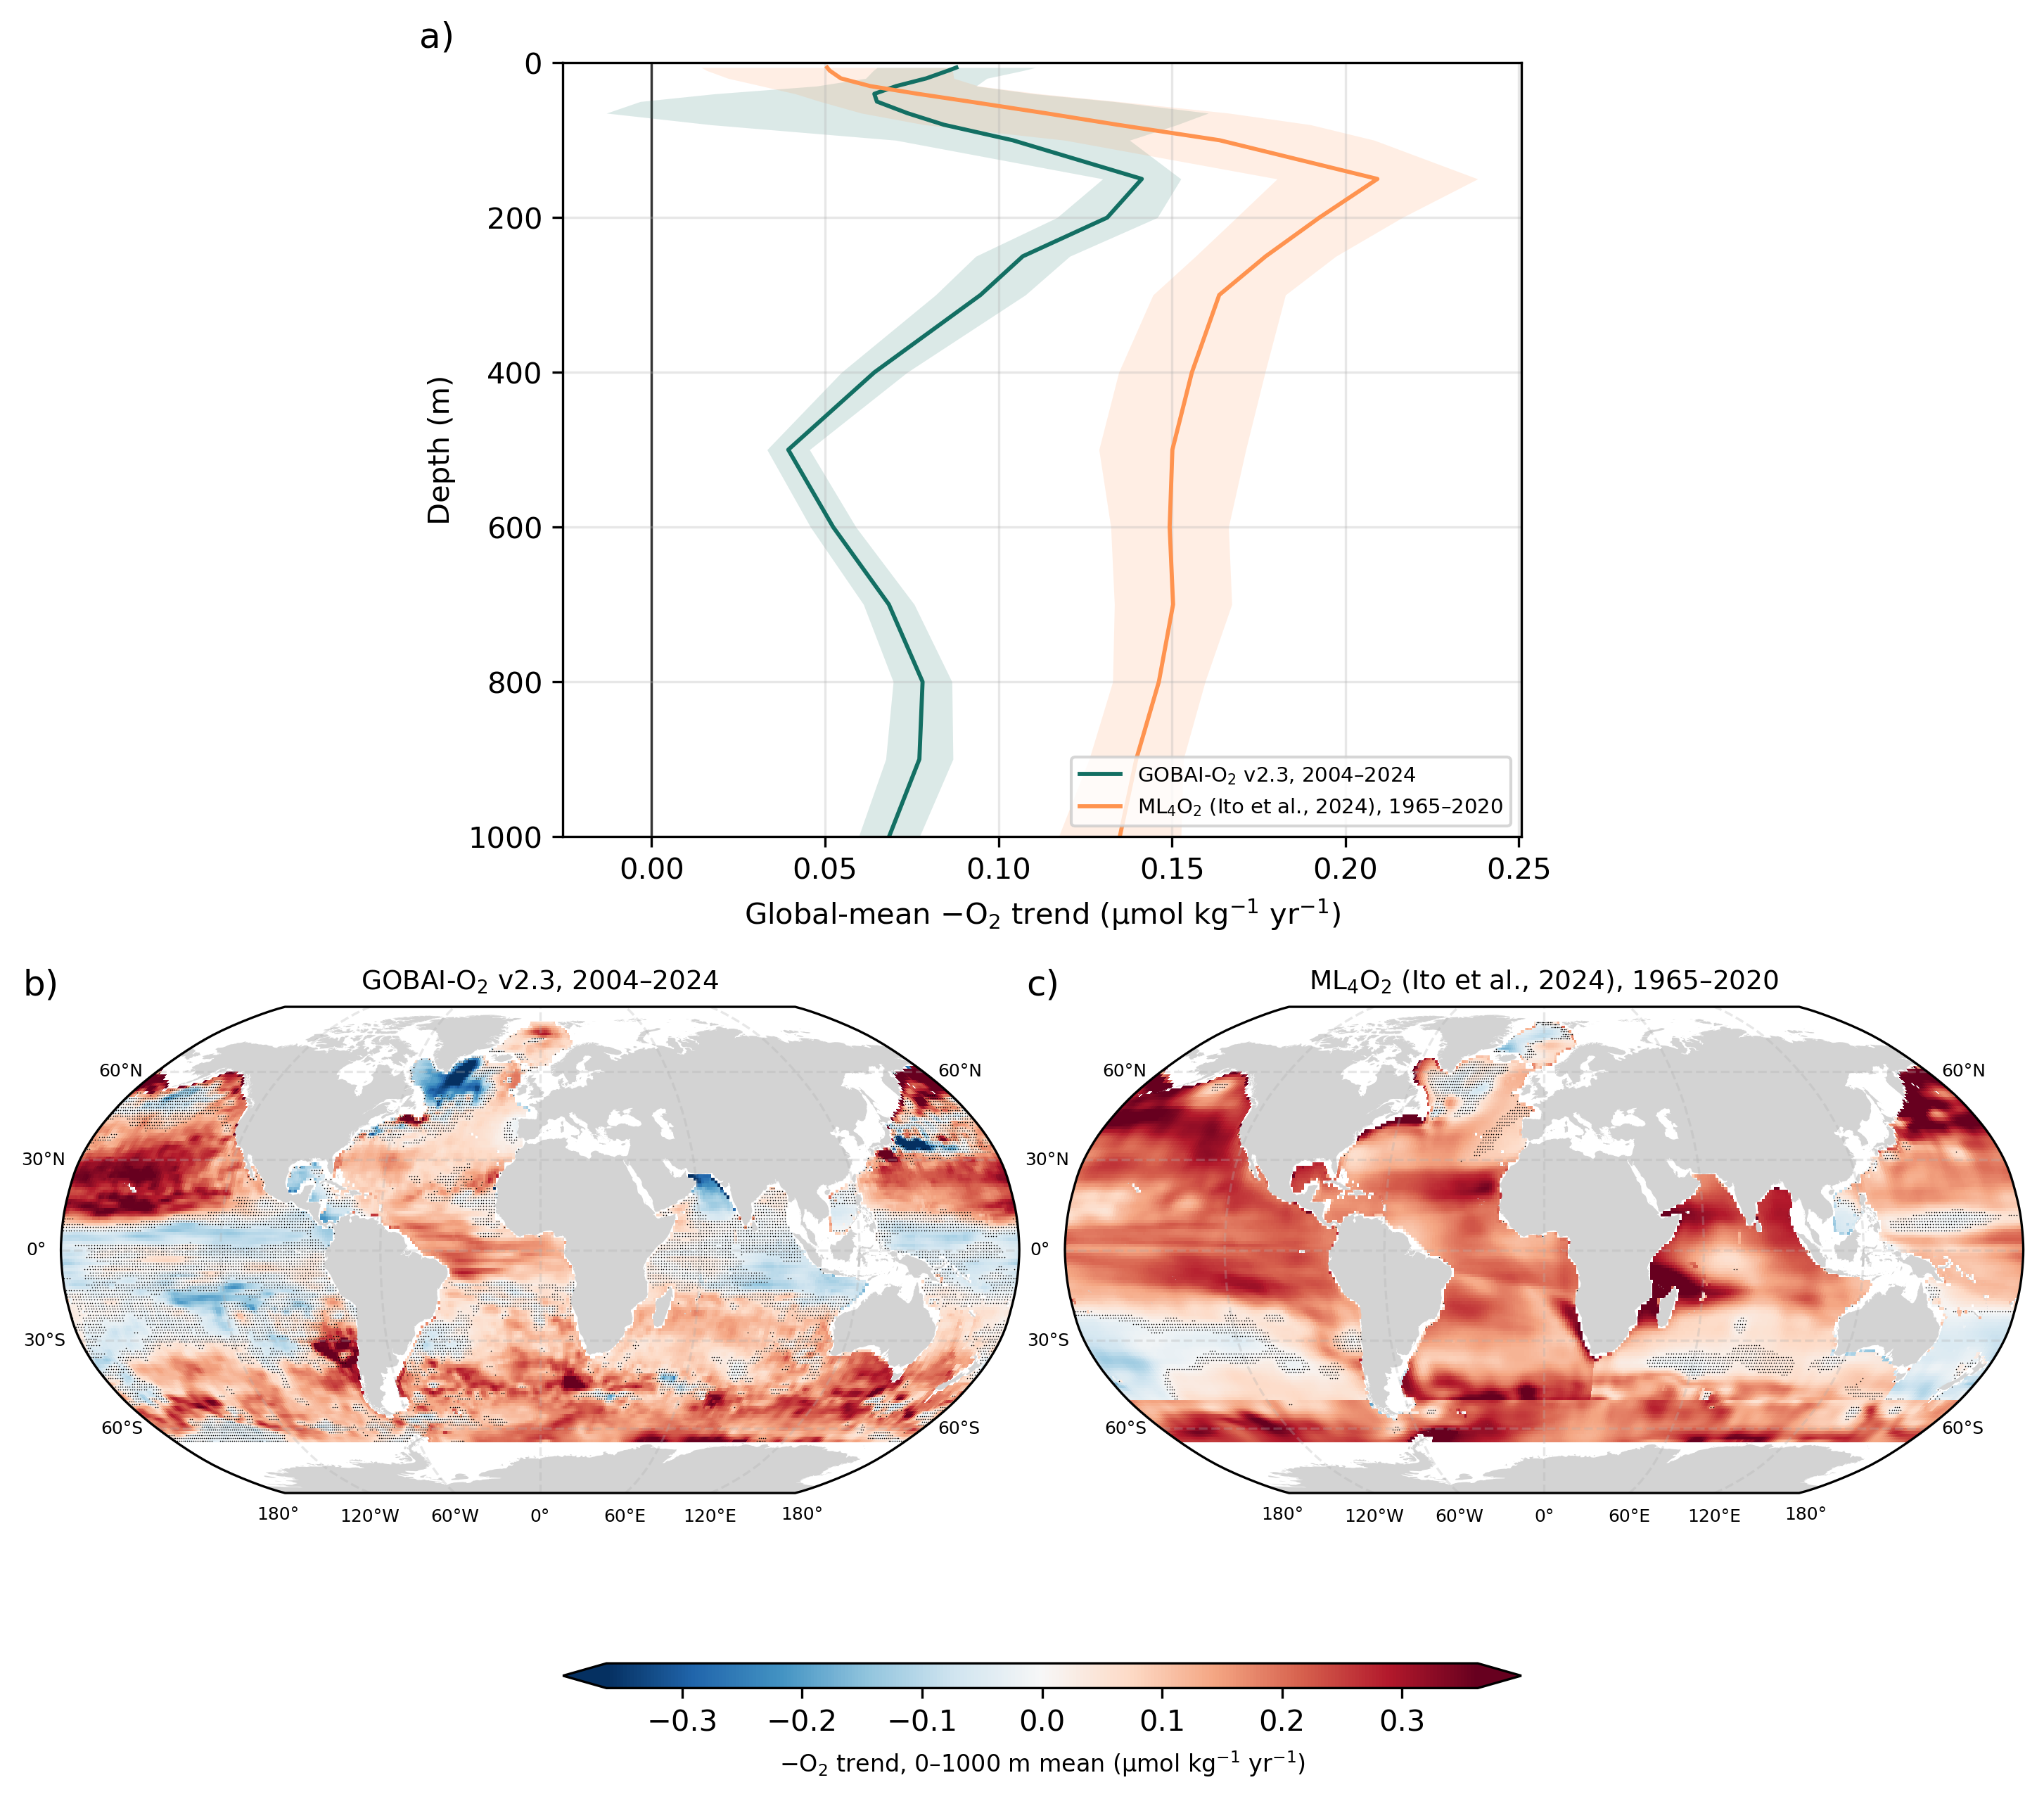

Saved: figs/FigureS3.png
GOBAI-O2 -O2, 2004-2024      0-1000 m +0.078 ± 0.007   100-1000 m +0.078   300-1000 m +0.067   (umol kg-1 yr-1, ±1 SE)
GOBAI-O2 AOU, 2004-2024      0-1000 m +0.047 ± 0.009   100-1000 m +0.052   300-1000 m +0.046   (umol kg-1 yr-1, ±1 SE)
ML4O2 -O2, 1965-2020         0-1000 m +0.151 ± 0.011   100-1000 m +0.157   300-1000 m +0.149   (umol kg-1 yr-1, ±1 SE)
ML4O2 -O2, 2004-2020         0-1000 m +0.236 ± 0.012   100-1000 m +0.240   300-1000 m +0.226   (umol kg-1 yr-1, ±1 SE)


In [2]:
# ============================================================
# TREND DETECTABILITY FIGURE (Reviewer 1, SI)
#   a) global-mean -O2 trend profiles, 0-1000 m: GOBAI-O2 v2.3 (2004-2024) and
#      ML4O2 (Ito et al., 2024; 1965-2020)
#   b) map: GOBAI-O2 v2.3 -O2 trend, 0-1000 m mean, 2004-2024
#   c) map: ML4O2 -O2 trend, 0-1000 m mean, 1965-2020
# The ML4O2 2004-2020 trend is printed only (Text S1), not plotted.
# ML4O2 provides O2 only (no T/S), so AOU cannot be computed for it. Both
# products are therefore compared as -O2 (AOU proxy). GOBAI AOU is computed
# only to print how close its AOU and -O2 trends are.
# Both products on the GOBAI grid and ML4O2 depth levels, over a common
# footprint (Mediterranean excluded). Trends: deseasonalised OLS; shading
# (±2 SE) and stippling (p >= 0.05) use lag-1 autocorrelation-adjusted SE.
# ============================================================

import numpy as np
import xarray as xr
import gsw
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import t as student_t

try:
    import koolstof as ks
    ks.parameterisations.aou_GG92
    HAVE_KS = True
except (ImportError, AttributeError):
    HAVE_KS = False

# ---------------- settings ----------------
GOBAI_FILE = "data/CONTENT_DIC_v2-3.nc"
ITO_FILE   = "data/o2_NN_ship+Argo_ensmean.nc"
OUT_FIG    = "figs/FigureS3.png"
P_GOBAI = ("2004-01-01", "2024-12-31")
P_ITO   = ("1965-01-01", "2020-12-31")
P_OVERLAP = ("2004-01-01", "2020-12-31")   # common period, printed only
ZMAX = 1000
MIN_VALID_FRAC = 0.9
PVAL_ALPHA = 0.05
C_GOBAI, C_ITO = "#136F63", "#FF934F"

# ---------------- helpers ----------------
def mask_mediterranean(lat, lon):
    lon180 = ((lon + 180) % 360) - 180
    return (lat >= 30) & (lat <= 46) & (lon180 >= -6) & (lon180 <= 37)

def deseason(da):
    return da.groupby("time.month") - da.groupby("time.month").mean("time")

def t_years(da):
    return ((da["time"] - da["time"].isel(time=0)) / np.timedelta64(1, "D")).values / 365.25

def trend_ar1(y, t):
    """OLS trend along axis 0, SE adjusted for lag-1 autocorrelation (NaN-aware)."""
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=float).reshape((-1,) + (1,) * (y.ndim - 1))
    m = np.isfinite(y)
    n = m.sum(0).astype(float)
    tt = np.where(m, t, np.nan)
    with np.errstate(invalid="ignore", divide="ignore"):
        dt = tt - np.nanmean(tt, 0)
        ybar = np.nanmean(y, 0)
        sxx = np.nansum(dt ** 2, 0)
        slope = np.nansum(dt * (y - ybar), 0) / sxx
        resid = y - ybar - slope * dt
        r1 = np.clip(np.nansum(resid[1:] * resid[:-1], 0) / np.nansum(resid ** 2, 0), 0, 0.99)
        neff = np.maximum(n * (1 - r1) / (1 + r1), 3.0)
        se = np.sqrt(np.nansum(resid ** 2, 0) / (n - 2) / sxx * (n - 2) / (neff - 2))
        p = 2 * student_t.sf(np.abs(slope / se), neff - 2)
    bad = n < 24
    return tuple(np.where(bad, np.nan, a) for a in (slope, se, p))

def o2sat(T, SP, p, lon, lat):
    """O2 solubility (umol kg-1), Garcia & Gordon (1992), as in 01A."""
    SA = gsw.SA_from_SP(SP, p, lon, lat)
    theta = gsw.pt0_from_t(SA, T, p)
    if HAVE_KS:
        return ks.parameterisations.aou_GG92(oxygen=0 * T, temperature=theta, salinity=SP)[0]
    return gsw.O2sol_SP_pt(SP, theta)

# ---------------- load ----------------
print("Loading GOBAI 0-1250 dbar...")
gob = xr.open_dataset(GOBAI_FILE)
g = gob[["oxy", "temp", "sal"]].sel(pres=slice(0, ZMAX * 1.25), time=slice(*P_GOBAI))
g = g.transpose("time", "pres", "lat", "lon").load()

ito = xr.open_dataset(ITO_FILE).sel(depth=slice(0, ZMAX), time=slice(*P_ITO))
g_lon = g["lon"].values
ito_lon = ito["lon"].values % 360
ito_lon = np.where(ito_lon < g_lon.min(), ito_lon + 360, ito_lon)
ito = ito.assign_coords(lon=ito_lon).sortby("lon")
ito = ito.sel(lat=g["lat"], lon=g["lon"], method="nearest")
ito = ito.assign_coords(lat=g["lat"].values, lon=g_lon)

depth = ito["depth"].values.astype(float)
pres_eq = gsw.p_from_z(-depth, 0.0)
edges = np.concatenate([[0], 0.5 * (depth[1:] + depth[:-1]), [depth[-1]]])
dz = np.diff(edges)

lat2d, lon2d = xr.broadcast(g["lat"], g["lon"])
med = mask_mediterranean(lat2d, lon2d).values
w2d = np.cos(np.deg2rad(lat2d.values))

def gmean(arr, mask):
    w = np.where(mask, w2d, 0.0)[None, :, :] * np.isfinite(arr)
    return np.nansum(arr * w, axis=(1, 2)) / w.sum(axis=(1, 2))

# ---------------- loop over depth levels ----------------
gm_aou_g, gm_o2_g, gm_o2_i = [], [], []
num_g = den_g = num_i = den_i = 0.0
for k in range(depth.size):
    print(f"Level {k + 1}/{depth.size}: {depth[k]:.0f} m")
    gk = g.interp(pres=pres_eq[k])
    sat = o2sat(gk["temp"], gk["sal"], pres_eq[k], gk["lon"], gk["lat"])
    sat = np.asarray(sat.transpose("time", "lat", "lon").values if hasattr(sat, "transpose") else sat)
    o2_g = gk["oxy"].values
    aou_g = sat - o2_g
    o2_i = ito["o2"].isel(depth=k).transpose("time", "lat", "lon").values

    fp = ((np.isfinite(aou_g).mean(0) >= MIN_VALID_FRAC)
          & (np.isfinite(o2_i).mean(0) >= MIN_VALID_FRAC) & ~med)
    gm_aou_g.append(gmean(aou_g, fp))
    gm_o2_g.append(gmean(o2_g, fp))
    gm_o2_i.append(gmean(o2_i, fp))

    ok_g = np.isfinite(o2_g) & fp
    num_g = num_g + np.where(ok_g, o2_g, 0.0) * dz[k]; den_g = den_g + ok_g * dz[k]
    ok_i = np.isfinite(o2_i) & fp
    num_i = num_i + np.where(ok_i, o2_i, 0.0) * dz[k]; den_i = den_i + ok_i * dz[k]

# ---------------- trends ----------------
def profile_trend(values, times, period=None):
    da = xr.DataArray(np.array(values).T, dims=("time", "depth"),
                      coords={"time": times.values, "depth": depth})
    if period is not None:
        da = da.sel(time=slice(*period))
    slope, se, _ = trend_ar1(deseason(da).values, t_years(da))
    return slope, se

def map_trend(num, den, times, period=None):
    with np.errstate(invalid="ignore"):
        arr = num / np.where(den > 0, den, np.nan)
    da = xr.DataArray(arr, dims=("time", "lat", "lon"),
                      coords={"time": times.values, "lat": g["lat"].values, "lon": g_lon})
    if period is not None:
        da = da.sel(time=slice(*period))
    slope, _, p = trend_ar1(deseason(da).values, t_years(da))
    return slope, p

def neg(trend_se):
    return -trend_se[0], trend_se[1]   # -O2: flip the trend, keep the SE

prof = {
    "gobai": neg(profile_trend(gm_o2_g, g["time"])),
    "ito": neg(profile_trend(gm_o2_i, ito["time"])),
    "ito_overlap": neg(profile_trend(gm_o2_i, ito["time"], P_OVERLAP)),
}
prof_aou_g = profile_trend(gm_aou_g, g["time"])   # for the AOU vs -O2 check only
map_g, p_g = map_trend(num_g, den_g, g["time"])
map_i, p_i = map_trend(num_i, den_i, ito["time"])
map_g, map_i = -map_g, -map_i

# ---------------- figure ----------------
fig = plt.figure(figsize=(12, 10), dpi=300)
gs = gridspec.GridSpec(3, 4, height_ratios=[1.25, 1, 0.04], hspace=0.22, wspace=0.1)

ax = fig.add_subplot(gs[0, 1:3])
for key, col, lab in [("gobai", C_GOBAI, "GOBAI-O$_2$ v2.3, 2004–2024"),
                      ("ito", C_ITO, "ML$_4$O$_2$ (Ito et al., 2024), 1965–2020")]:
    tr, se = prof[key]
    ax.plot(tr, depth, color=col, lw=1.4, label=lab)
    ax.fill_betweenx(depth, tr - 2 * se, tr + 2 * se, color=col, alpha=0.15, lw=0)
ax.axvline(0, color="k", lw=0.8, zorder=0)
ax.set_ylim(ZMAX, 0)
ax.set_xlabel("Global-mean −O$_2$ trend (µmol kg$^{-1}$ yr$^{-1}$)")
ax.set_ylabel("Depth (m)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right")
ax.text(-0.15, 1.02, "a)", transform=ax.transAxes, fontsize=12)

allv = np.concatenate([m[np.isfinite(m)] for m in (map_g, map_i)])
v = np.nanpercentile(np.abs(allv), 98)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v)
land = cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="none", facecolor="lightgrey")

map_axes = []
for lab, title, field, p, pos in [
    ("b)", "GOBAI-O$_2$ v2.3, 2004–2024", map_g, p_g, gs[1, 0:2]),
    ("c)", "ML$_4$O$_2$ (Ito et al., 2024), 1965–2020", map_i, p_i, gs[1, 2:4]),
]:
    axm = fig.add_subplot(pos, projection=ccrs.Robinson())
    axm.set_global()
    axm.add_feature(land)
    gl = axm.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = cticker.LongitudeFormatter()
    gl.yformatter = cticker.LatitudeFormatter()
    gl.xlabel_style = {"size": 6}
    gl.ylabel_style = {"size": 6}
    im = axm.pcolormesh(lon2d.values, lat2d.values, field, transform=ccrs.PlateCarree(),
                        cmap="RdBu_r", norm=norm, shading="auto")
    nonsig = np.isfinite(field) & (p >= PVAL_ALPHA)
    axm.scatter(lon2d.values[nonsig], lat2d.values[nonsig], s=0.6, c="k", marker=".",
                linewidths=0, transform=ccrs.PlateCarree(), zorder=4)
    axm.set_title(title, fontsize=9)
    axm.text(-0.04, 1.08, lab, transform=axm.transAxes, fontsize=12, va="top")
    map_axes.append(axm)

cax = fig.add_subplot(gs[2, 1:3])
cbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend="both")
cbar.set_label("−O$_2$ trend, 0–1000 m mean (µmol kg$^{-1}$ yr$^{-1}$)", fontsize=8)

fig.savefig(OUT_FIG, bbox_inches="tight", dpi=300)
plt.show()
print("Saved:", OUT_FIG)

# ---------------- numbers for the reply ----------------
def layer_mean(x, z0, z1):
    s = (depth >= z0) & (depth <= z1) & np.isfinite(x)
    return (x[s] * dz[s]).sum() / dz[s].sum()

rows = [("GOBAI-O2 -O2, 2004-2024", prof["gobai"]),
        ("GOBAI-O2 AOU, 2004-2024", prof_aou_g),
        ("ML4O2 -O2, 1965-2020", prof["ito"]),
        ("ML4O2 -O2, 2004-2020", prof["ito_overlap"])]
for lab, (tr, se) in rows:
    print(f"{lab:28s} 0-1000 m {layer_mean(tr, 0, 1000):+.3f} ± {layer_mean(se, 0, 1000):.3f}"
          f"   100-1000 m {layer_mean(tr, 100, 1000):+.3f}   300-1000 m {layer_mean(tr, 300, 1000):+.3f}"
          f"   (umol kg-1 yr-1, ±1 SE)")

**____________________________________________________________________________________________________________________________**


## Figure S4
### Annual mean DIC from GCC-DIC at 10, 300, 500 and 1000 m

In [21]:
import xarray as xr

# Load dataset with appropriate chunks
ds = xr.open_dataset('data/CONTENT_DIC_v2-3.nc')

# Only keep data down to 1000m
ds = ds.where(ds.pres <= 1000, drop=True)

# Only keep variable of interest
# ds = ds[['CT']]

In [22]:
ds

<xarray.Dataset> Size: 19GB
Dimensions:       (time: 252, pres: 44, lat: 145, lon: 360)
Coordinates:
  * time          (time) datetime64[ns] 2kB 2004-01-16 2004-02-16 ... 2024-12-16
  * pres          (pres) float32 176B 2.5 10.0 20.0 30.0 ... 900.0 950.0 1e+03
  * lat           (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 77.5 78.5 79.5
  * lon           (lon) float32 1kB 20.5 21.5 22.5 23.5 ... 377.5 378.5 379.5
Data variables:
    o2            (time, pres, lat, lon) float32 2GB 352.1 352.2 ... nan nan
    uncer         (time, pres, lat, lon) float32 2GB 12.2 12.32 ... nan nan
    temp          (time, pres, lat, lon) float32 2GB -0.033 -0.045 ... nan nan
    sal           (time, pres, lat, lon) float32 2GB 33.75 33.74 ... nan nan
    oxy           (time, lon, lat, pres) float32 2GB 352.1 352.6 ... nan nan
    CT            (time, lon, lat, pres) float32 2GB 2.156e+03 2.157e+03 ... nan
    CT_sigma      (time, lon, lat, pres) float32 2GB 12.21 12.13 ... nan nan
    CT_sigma_min  (time, lon, lat, pres) float32 2GB 9.455 9.372 ... nan nan

In [23]:
surface = ds['CT'].mean(dim='time').isel(pres=1)
middepth = ds['CT'].mean(dim='time').isel(pres=24)
middeep = ds['CT'].mean(dim='time').isel(pres=33)
deep = ds['CT'].mean(dim='time').isel(pres=43)

In [24]:
surface = surface.transpose()
middepth = middepth.transpose()
middeep = middeep.transpose()
deep = deep.transpose()

In [25]:
import numpy as np

# Define a Mediterranean mask function
def mask_mediterranean(data):
    lat = data.lat
    lon = data.lon

    # Adjust longitudes if necessary (0 to 360 → -180 to 180)
    lon_corrected = lon.where(lon <= 180, lon - 360)

    # Mediterranean bounding box (rough estimate)
    med_mask = ((lat > 30) & (lat < 46)) & ((lon_corrected > -6) & (lon_corrected < 37))

    # Apply mask to data
    data = data.where(~med_mask, np.nan)
    return data

# Apply mask to each dataset
surface = mask_mediterranean(surface)
middepth = mask_mediterranean(middepth)
middeep = mask_mediterranean(middeep)
deep = mask_mediterranean(deep)


/tmp/ipykernel_4073006/3124871179.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


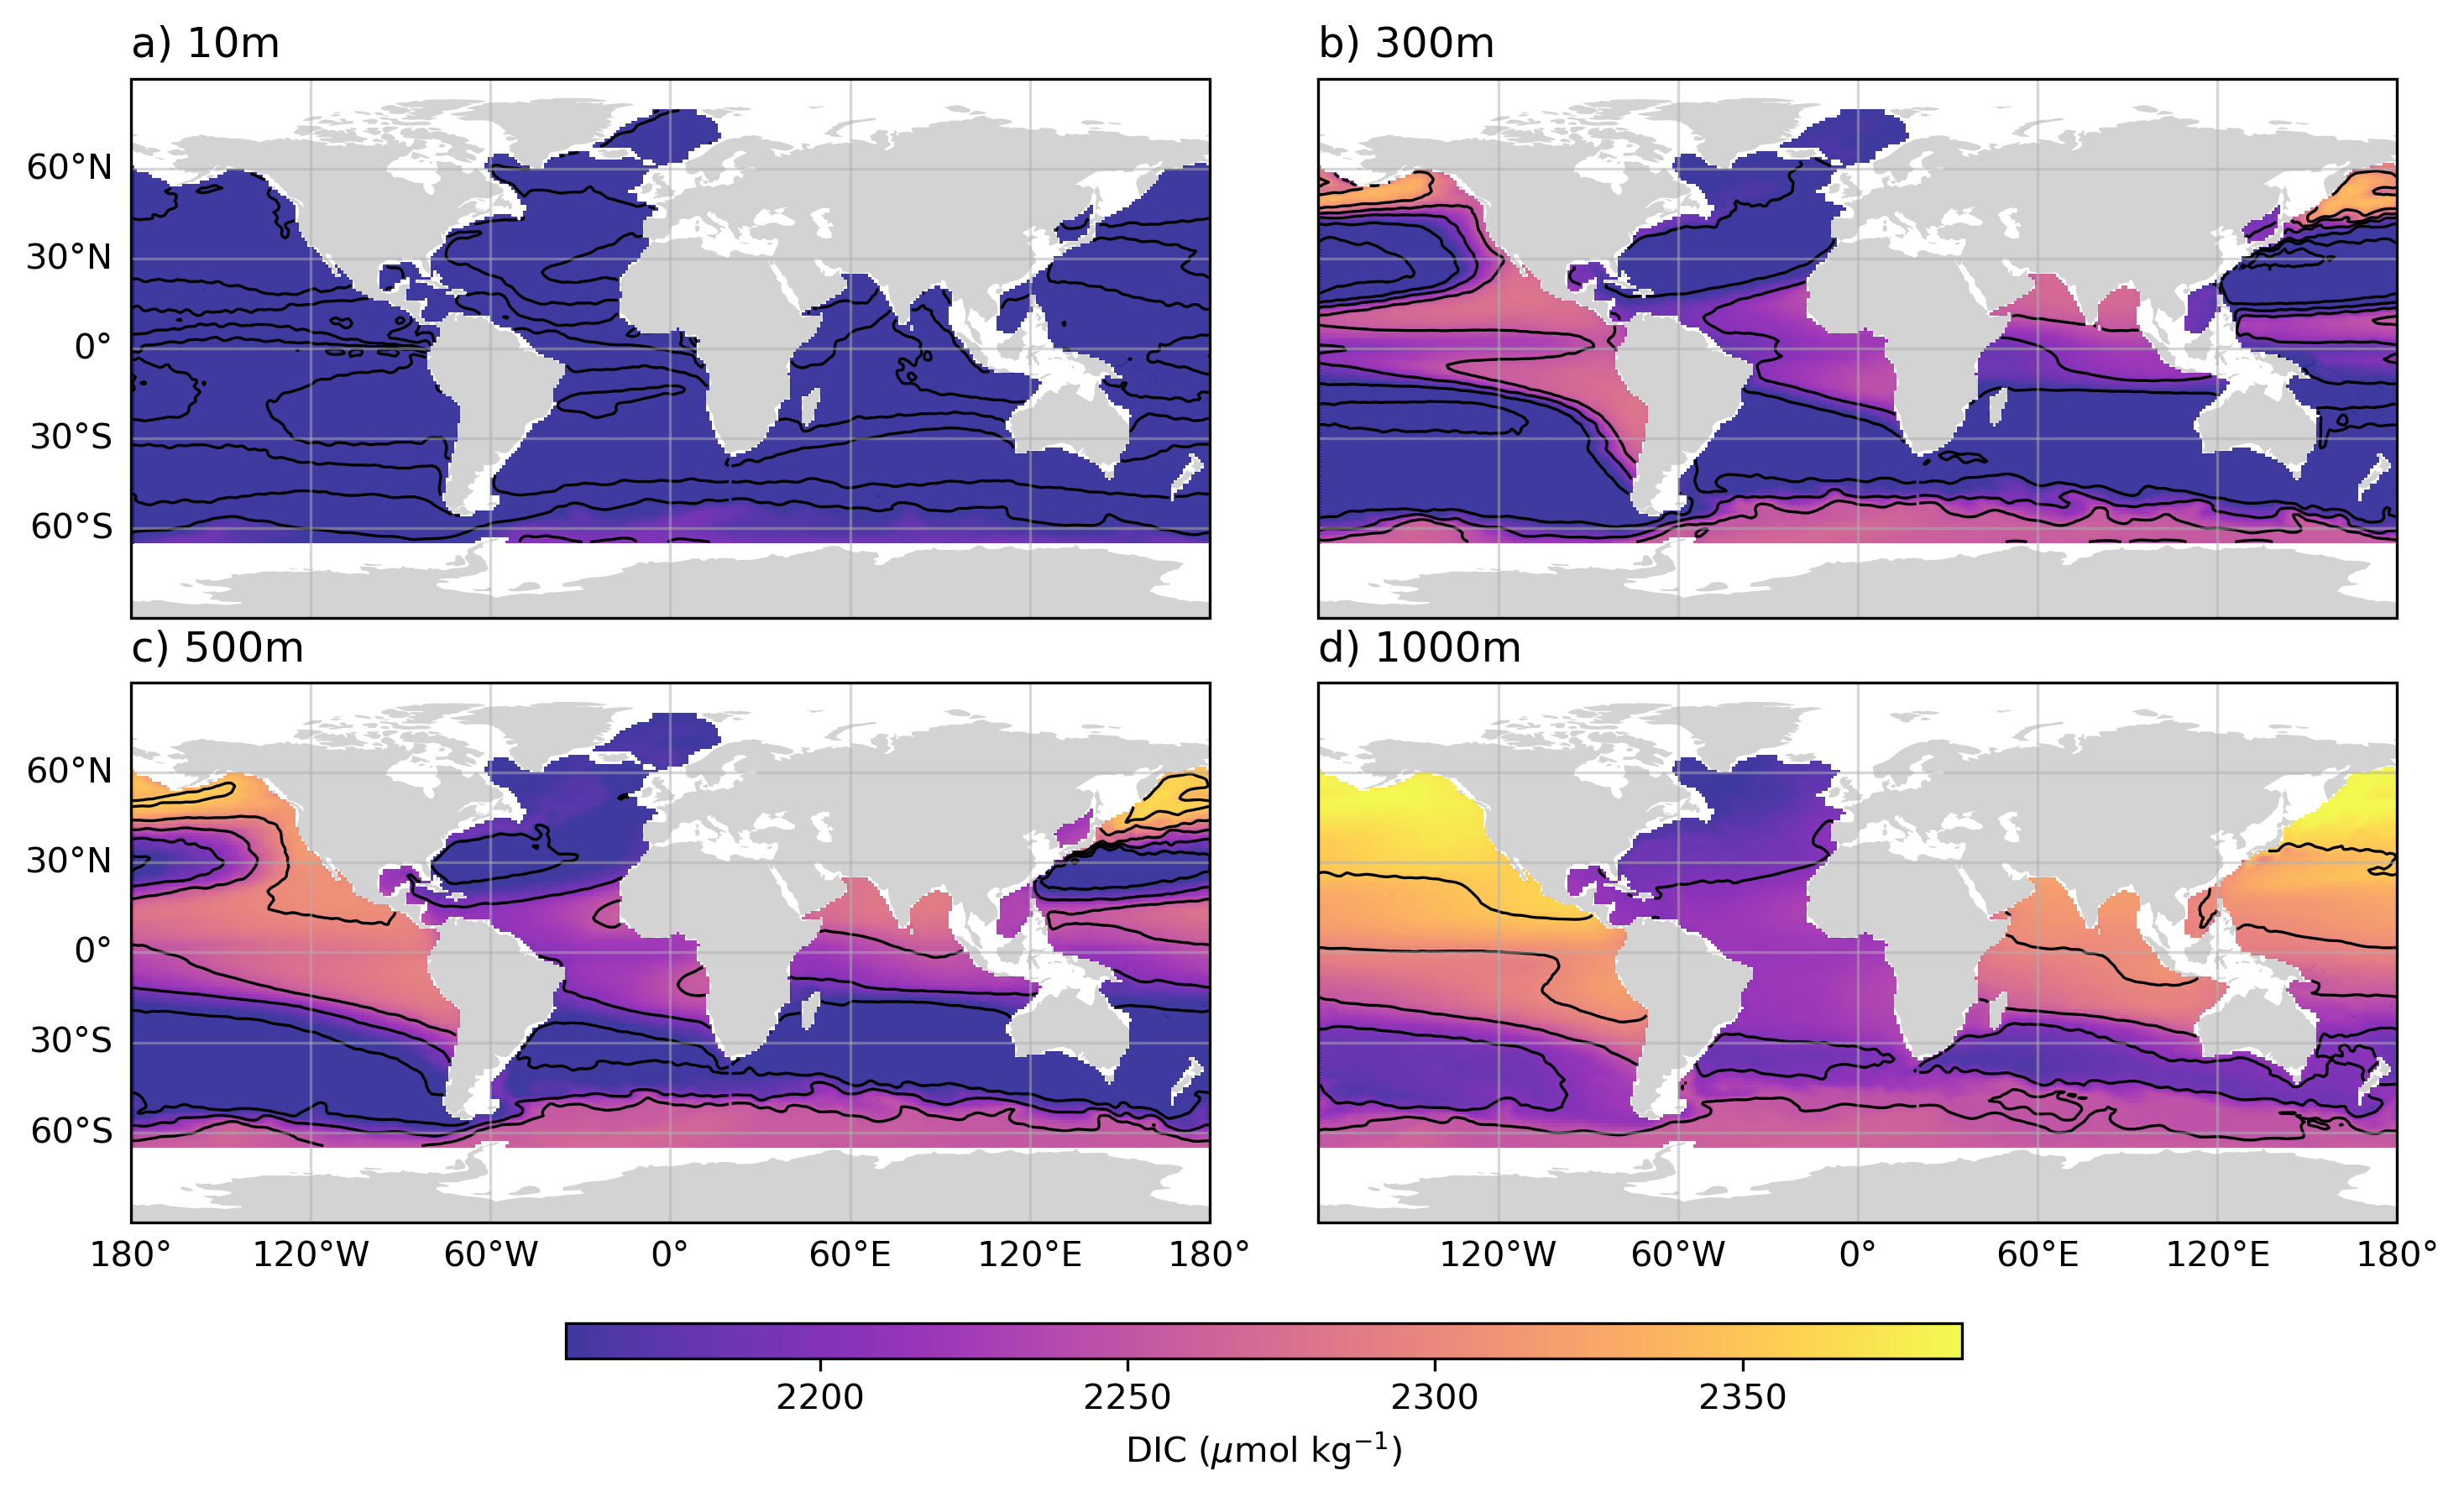

In [26]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from matplotlib.colors import BoundaryNorm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize

# Create figure
fig, axs = plt.subplots(2, 2, figsize=(10, 6), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})

# Contour levels every 50 μmol kg⁻¹
contour_levels = list(range(0, int(max(surface.max(), middepth.max(), middeep.max(), deep.max())) + 50, 50))

# Find the overall maximum value across all datasets
min_value = max(
    surface.min().compute().item(),
    middepth.min().compute().item(),
    middeep.min().compute().item(),
    deep.min().compute().item()
)
max_value = max(
    surface.max().compute().item(),
    middepth.max().compute().item(),
    middeep.max().compute().item(),
    deep.max().compute().item()
)

# Create a normalization object with a range of 0 to the overall maximum
norm = Normalize(vmin=min_value, vmax=max_value)

# Add different depths distributions with the same normalization
pcolormesh_plots = [
    axs[0, 0].pcolormesh(surface.lon, surface.lat, surface, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[0, 1].pcolormesh(middepth.lon, middepth.lat, middepth, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 0].pcolormesh(middeep.lon, middeep.lat, middeep, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 1].pcolormesh(deep.lon, deep.lat, deep, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
]

# Add features and contours to all subplots
subplot_labels = ['a) 10m', 'b) 300m', 'c) 500m', 'd) 1000m']
data_sets = [surface, middepth, middeep, deep]

for ax, label, data, row, col in zip(axs.flat, subplot_labels, data_sets, [0, 0, 1, 1], [0, 1, 0, 1]):
    ax.add_feature(cfeature.LAND, edgecolor='none', facecolor='lightgrey')
    ax.set_ylim(-90, 90)

    # Add contour lines
    ax.contour(data.lon, data.lat, data, levels=contour_levels, colors='black', linewidths=0.8, transform=ccrs.PlateCarree())

    # Improve grid
    gl = ax.gridlines(draw_labels=True, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (col == 0)
    gl.bottom_labels = (row == 1)

    # Add text to the upper left corner of each subplot
    ax.text(0., 1.1, label, transform=ax.transAxes, fontsize=12, verticalalignment='top')

# Create a common colorbar
cbar = fig.colorbar(
    pcolormesh_plots[0],
    ax=axs,
    orientation='horizontal',
    fraction=0.03,
    pad=0.1,
    aspect=40,
)

cbar.set_label(r'DIC ($\mu$mol kg$^{-1}$)')

plt.tight_layout()
# plt.subplots_adjust(hspace=0.1, wspace=0.1)
# Adjust layout to create more space at the bottom
plt.subplots_adjust(bottom=0.2)
plt.savefig('figs/FigureS4.png', bbox_inches='tight', dpi=300)
plt.show()



**____________________________________________________________________________________________________________________________**


## Figure S5
### Annual mean TA from GCC-DIC at 10, 300, 500 and 1000 m

In [28]:
# Load dataset with appropriate chunks
ds = xr.open_dataset('data/CONTENT_AT_v2-3.nc')

# Only keep data down to 1000m
ds = ds.where(ds.pres <= 1000, drop=True)

# Only keep variable of interest
# ds = ds[['CT']]

In [29]:
surface = ds['AT'].mean(dim='time').isel(pres=1)
middepth = ds['AT'].mean(dim='time').isel(pres=24)
middeep = ds['AT'].mean(dim='time').isel(pres=33)
deep = ds['AT'].mean(dim='time').isel(pres=43)

In [30]:
surface = surface.transpose()
middepth = middepth.transpose()
middeep = middeep.transpose()
deep = deep.transpose()

In [31]:
# Define a Mediterranean mask function
def mask_mediterranean(data):
    lat = data.lat
    lon = data.lon

    # Adjust longitudes if necessary (0 to 360 → -180 to 180)
    lon_corrected = lon.where(lon <= 180, lon - 360)

    # Mediterranean bounding box (rough estimate)
    med_mask = ((lat > 30) & (lat < 46)) & ((lon_corrected > -6) & (lon_corrected < 37))

    # Apply mask to data
    data = data.where(~med_mask, np.nan)
    return data

# Apply mask to each dataset
surface = mask_mediterranean(surface)
middepth = mask_mediterranean(middepth)
middeep = mask_mediterranean(middeep)
deep = mask_mediterranean(deep)


/tmp/ipykernel_4073006/1568014405.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


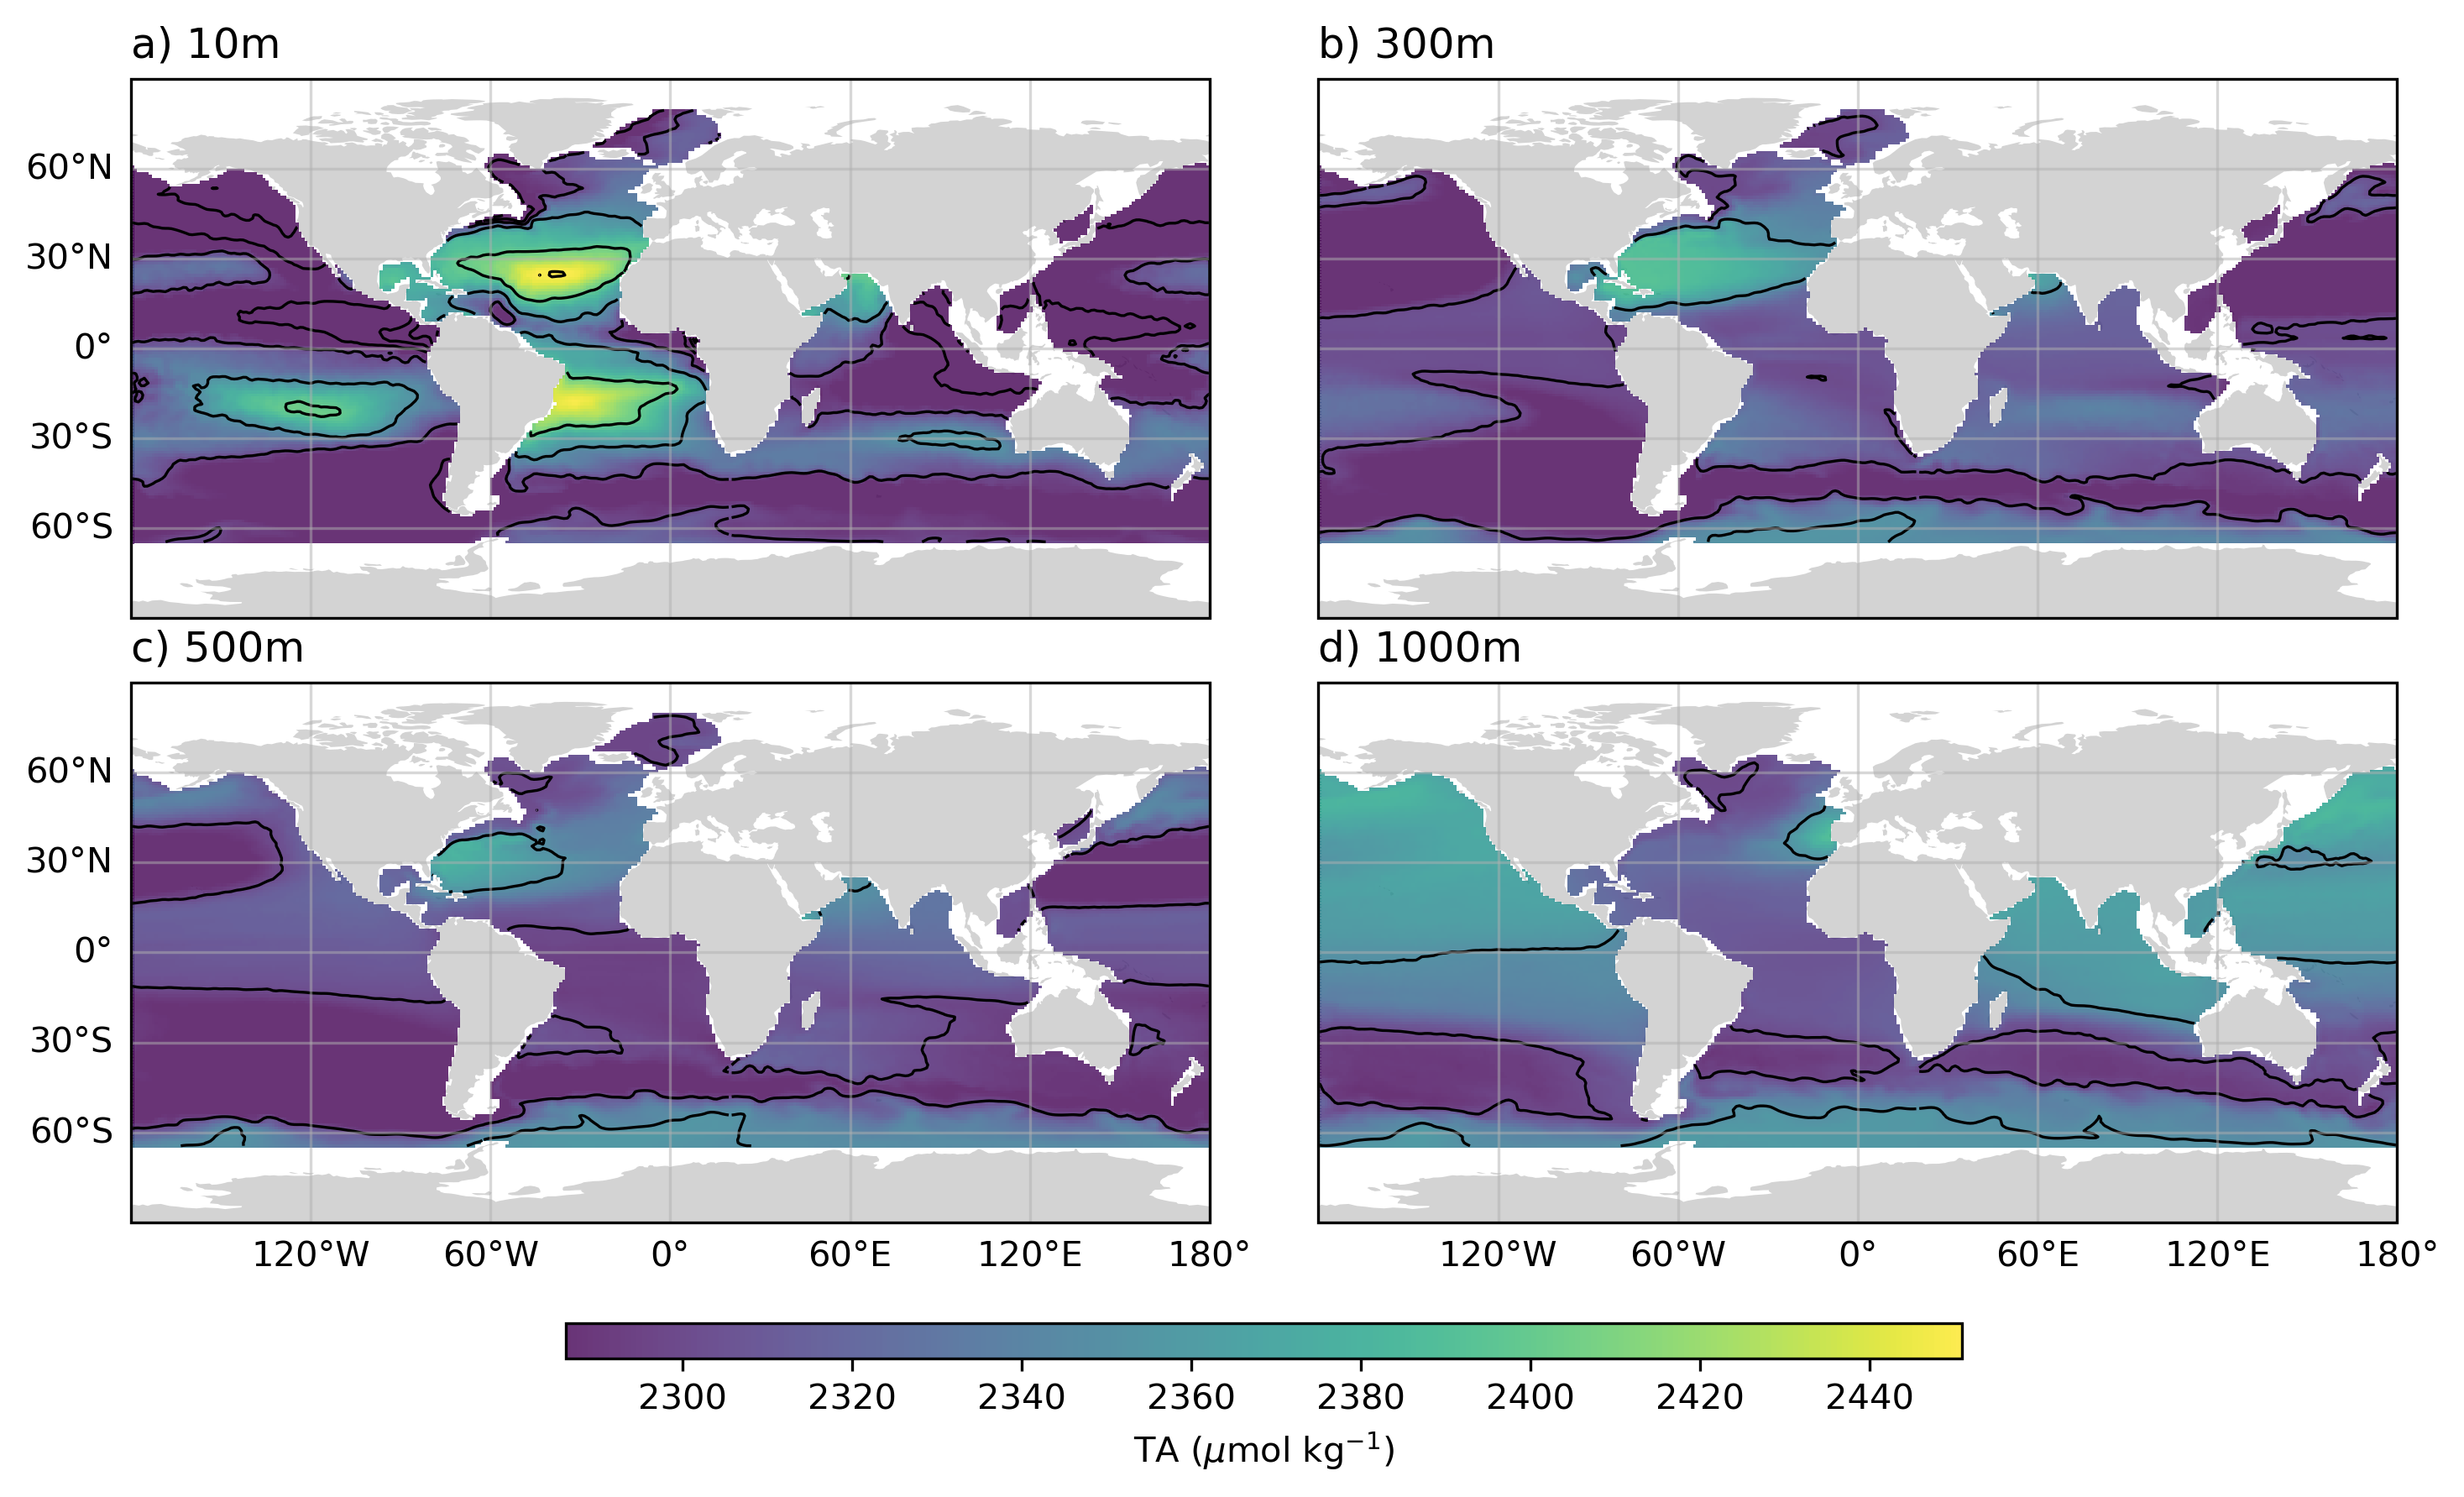

In [32]:
# Create figure
fig, axs = plt.subplots(2, 2, figsize=(10, 6), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})

# Contour levels every 50 μmol kg⁻¹
contour_levels = list(range(0, int(max(surface.max(), middepth.max(), middeep.max(), deep.max())) + 50, 50))

# Find the overall maximum value across all datasets
min_value = max(
    surface.min().compute().item(),
    middepth.min().compute().item(),
    middeep.min().compute().item(),
    deep.min().compute().item()
)
max_value = max(
    surface.max().compute().item(),
    middepth.max().compute().item(),
    middeep.max().compute().item(),
    deep.max().compute().item()
)

# Create a normalization object with a range of 0 to the overall maximum
norm = Normalize(vmin=min_value, vmax=max_value)

# Add different depths distributions with the same normalization
pcolormesh_plots = [
    axs[0, 0].pcolormesh(surface.lon, surface.lat, surface, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[0, 1].pcolormesh(middepth.lon, middepth.lat, middepth, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 0].pcolormesh(middeep.lon, middeep.lat, middeep, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 1].pcolormesh(deep.lon, deep.lat, deep, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
]

# Add features and contours to all subplots
subplot_labels = ['a) 10m', 'b) 300m', 'c) 500m', 'd) 1000m']
data_sets = [surface, middepth, middeep, deep]

for ax, label, data, row, col in zip(axs.flat, subplot_labels, data_sets, [0, 0, 1, 1], [0, 1, 0, 1]):
    ax.add_feature(cfeature.LAND, edgecolor='none', facecolor='lightgrey')
    ax.set_ylim(-90, 90)

    # Add contour lines
    ax.contour(data.lon, data.lat, data, levels=contour_levels, colors='black', linewidths=0.8, transform=ccrs.PlateCarree())

    # Improve grid
    gl = ax.gridlines(draw_labels=True, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (col == 0)
    gl.bottom_labels = (row == 1)

    # Add text to the upper left corner of each subplot
    ax.text(0., 1.1, label, transform=ax.transAxes, fontsize=12, verticalalignment='top')

# Create a common colorbar
cbar = fig.colorbar(
    pcolormesh_plots[0],
    ax=axs,
    orientation='horizontal',
    fraction=0.03,
    pad=0.1,
    aspect=40,
)

cbar.set_label(r'TA ($\mu$mol kg$^{-1}$)')

plt.tight_layout()
# plt.subplots_adjust(hspace=0.1, wspace=0.1)
# Adjust layout to create more space at the bottom
plt.subplots_adjust(bottom=0.2)

plt.savefig('figs/FigureS5.png', bbox_inches='tight', dpi=300)
plt.show()



**____________________________________________________________________________________________________________________________**


## Figure S6
### Basin pixels used to compare pressure and neutral density

The analysis is made in pressure space. The neutral density (γ<sup>n</sup>) analysis is computationally heavy and requires large storage, so it is not included in this repository; it is available on request.

**____________________________________________________________________________________________________________________________**


## Figure S7
### Residuals of the pressure/γ<sup>n</sup> ratio over time in each basin

The analysis is made in pressure space. The neutral density (γ<sup>n</sup>) analysis is computationally heavy and requires large storage, so it is not included in this repository; it is available on request.

**____________________________________________________________________________________________________________________________**


## Figure S8
### Range of pressure variations at each depth level in each basin

The analysis is made in pressure space. The neutral density (γ<sup>n</sup>) analysis is computationally heavy and requires large storage, so it is not included in this repository; it is available on request.

**____________________________________________________________________________________________________________________________**


## Figure S9
### Profile selection at the time-series stations (all samples in black, selected in blue)

#### Relevant script: ocean-time-series-bcp/scripts/01_build_spots_dataset.py

In [ ]:
import subprocess
import sys
from IPython.display import Image, display

subprocess.run([sys.executable, "scripts/01_build_spots_dataset.py"], cwd="ocean-time-series-bcp", check=True)
display(Image("figs/FigureS9.png", width=800))

**____________________________________________________________________________________________________________________________**


## Figure S10
### Fig. 4 in neutral density space

The analysis is made in pressure space. The neutral density (γ<sup>n</sup>) analysis is computationally heavy and requires large storage, so it is not included in this repository; it is available on request.

**____________________________________________________________________________________________________________________________**


## Figure S11
### In situ vs GCC-DIC depth-weighted ΔDIC<sub>soft</sub> at the time-series stations

#### Relevant script: ocean-time-series-bcp/scripts/05_figS_insitu_vs_gccdic_scatter.py

In [ ]:
import subprocess
import sys
from IPython.display import Image, display

subprocess.run([sys.executable, "scripts/05_figS_insitu_vs_gccdic_scatter.py"], cwd="ocean-time-series-bcp", check=True)
display(Image("figs/FigureS11.png", width=800))

**____________________________________________________________________________________________________________________________**


## Figure S12
### Maximum climatological mixed layer depth (Holte et al., 2017)

Not reproduced in this repository (made in an earlier version of the analysis).

**____________________________________________________________________________________________________________________________**


## Figure S13
### Sign agreement between 0–200 m N<sup>2</sup> and ΔDIC<sub>soft</sub> trends

#### Relevant scripts: 06_N2_stratification_trend.py, 07A_DIC_band_0_200.py

Loading datasets...
Area fraction of each combination (0-200 m):
                             all cells   robust cells
N2 ↑, DICsoft ↑                  51.3%          62.5%
N2 ↑, DICsoft ↓                  30.0%          17.7%
N2 ↓, DICsoft ↑                  13.7%          16.3%
N2 ↓, DICsoft ↓                   4.9%           3.5%
Figure saved to: figs/FigureS13.png


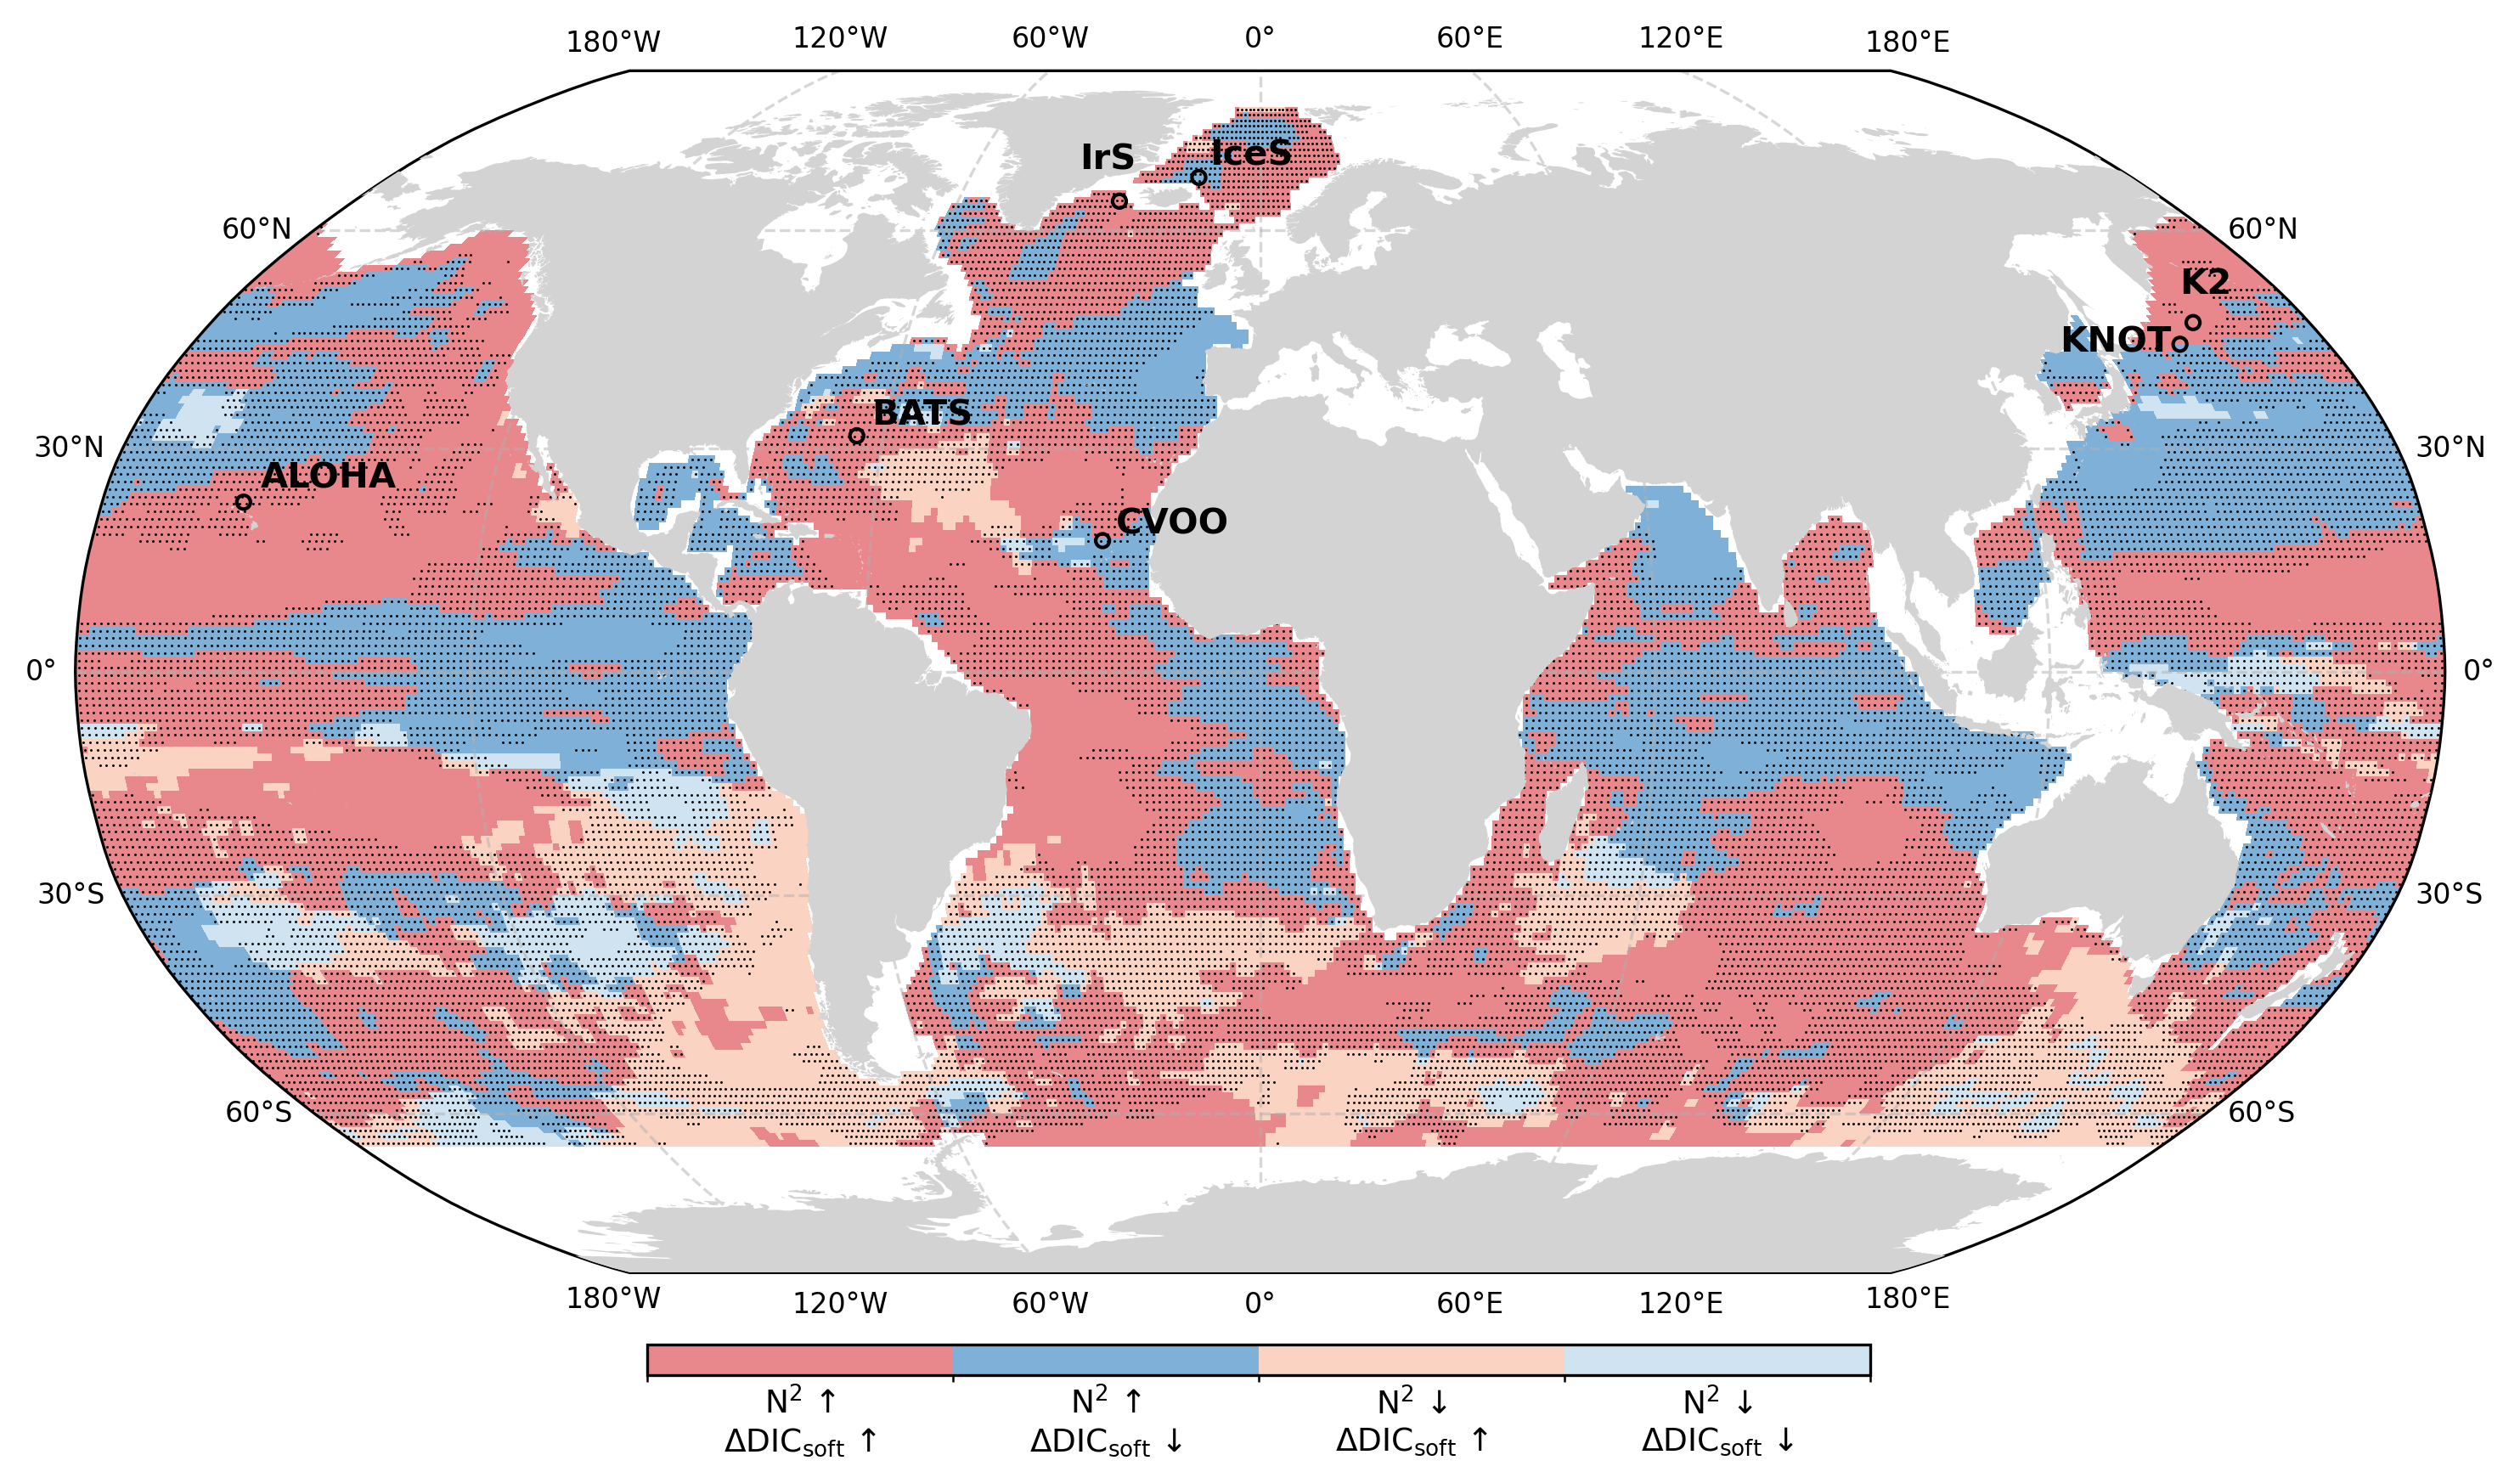

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Polygon
import xarray as xr
import matplotlib.ticker as mticker
import cartopy.mpl.ticker as cticker

# -------------------------------------------------------------------
# USER SETTINGS
# -------------------------------------------------------------------
ZERO_TREND_TOL = 1e-12

# Monte Carlo robustness threshold (same as Fig. 3):
# a pixel is considered robust only if >= 80% of iterations are
# significant and have the same sign
ROBUSTNESS_THRESHOLD = 0.80
NUM_ITERATIONS = 1000

# Stipple appearance
STIPPLE_SIZE = 2.0
STIPPLE_COLOR = "black"

# Categories (sign of N2 trend, sign of DICsoft trend)
CATEGORY_LABELS = {
    1: "N$^2$ ↑\nΔDIC$_{\\mathrm{soft}}$ ↑",
    2: "N$^2$ ↑\nΔDIC$_{\\mathrm{soft}}$ ↓",
    3: "N$^2$ ↓\nΔDIC$_{\\mathrm{soft}}$ ↑",
    4: "N$^2$ ↓\nΔDIC$_{\\mathrm{soft}}$ ↓",
}
CATEGORY_COLORS = ["#e8888c", "#7fb1d8", "#fbd3c2", "#cfe3f1"]  # lightened so stippling stays visible

# Mediterranean white rectangle in PlateCarree coordinates
MED_POLYGON = [
    (-6.5, 35.0),
    (-6.5, 36.8),
    (-4.5, 37.4),
    (-2.0, 39.0),
    (1.5, 42.3),
    (5.5, 44.5),
    (9.5, 45.8),
    (14.5, 46.5),
    (19.5, 46.2),
    (24.0, 45.0),
    (28.5, 42.8),
    (33.0, 39.0),
    (36.8, 35.2),
    (36.8, 30.0),
    (33.0, 29.6),
    (28.0, 29.6),
    (22.0, 29.8),
    (16.0, 30.0),
    (10.0, 30.0),
    (4.0, 30.0),
    (-1.0, 30.8),
    (-5.0, 33.0),
    (-6.5, 35.0),
]

# -------------------------------------------------------------------
# Paths
# -------------------------------------------------------------------
dic_path = "data/processing_steps/07A_DIC_band_0_200_monte_carlo.nc"
n2_path = "data/processing_steps/06_N2_stratification_trend.nc"
output_figure = "figs/FigureS13.png"

# -------------------------------------------------------------------
# Load datasets and align grids
# -------------------------------------------------------------------
print("Loading datasets...")
dic_ds = xr.load_dataset(dic_path)
n2_da = xr.load_dataset(n2_path)["trend_N2bar_0_200_peryr"]

dic_ds, n2_da = xr.align(dic_ds, n2_da, join="inner")

# -------------------------------------------------------------------
# Extract coordinates
# -------------------------------------------------------------------
lon = dic_ds.coords["lon"].values
lat = dic_ds.coords["lat"].values

# Convert longitudes to [-180, 180]
lon_wrapped = ((lon + 180) % 360) - 180

# Sort by longitude so plotting is continuous
sort_idx = np.argsort(lon_wrapped)
lon_wrapped = lon_wrapped[sort_idx]

# -------------------------------------------------------------------
# Extract variables and reorder longitude dimension
# -------------------------------------------------------------------
dic_data = dic_ds["soft_pump_aou_change"].transpose("lat", "lon").values[:, sort_idx]
uncertainty_data = dic_ds["soft_pump_aou_change_uncertainty"].transpose("lat", "lon").values[:, sort_idx]
sig_pos_count_data = dic_ds["soft_pump_aou_change_significant_positive_count"].transpose("lat", "lon").values[:, sort_idx]
sig_neg_count_data = dic_ds["soft_pump_aou_change_significant_negative_count"].transpose("lat", "lon").values[:, sort_idx]
n2_data = n2_da.transpose("lat", "lon").values[:, sort_idx]

# Build 2D coordinates after sorting
lon_2d, lat_2d = np.meshgrid(lon_wrapped, lat)

# -------------------------------------------------------------------
# Build masks for valid ocean plotting
# -------------------------------------------------------------------
finite_mask = (
    np.isfinite(dic_data)
    & np.isfinite(uncertainty_data)
    & np.isfinite(sig_pos_count_data)
    & np.isfinite(sig_neg_count_data)
    & np.isfinite(n2_data)
)

nonzero_trend_mask = np.abs(dic_data) > ZERO_TREND_TOL

ocean_valid_mask = finite_mask & (
    (np.abs(dic_data) > ZERO_TREND_TOL) |
    (np.abs(uncertainty_data) > ZERO_TREND_TOL)
)

# -------------------------------------------------------------------
# Monte Carlo robustness using 80% rule (on DICsoft)
# -------------------------------------------------------------------
robust_positive_mask = (sig_pos_count_data / NUM_ITERATIONS) >= ROBUSTNESS_THRESHOLD
robust_negative_mask = (sig_neg_count_data / NUM_ITERATIONS) >= ROBUSTNESS_THRESHOLD
significant_mask = (robust_positive_mask | robust_negative_mask) & ocean_valid_mask
nonsignificant_mask = (~significant_mask) & ocean_valid_mask

# -------------------------------------------------------------------
# Sign-combination categories
# -------------------------------------------------------------------
category = np.full(dic_data.shape, np.nan)
category[ocean_valid_mask & (n2_data > 0) & (dic_data > 0)] = 1
category[ocean_valid_mask & (n2_data > 0) & (dic_data < 0)] = 2
category[ocean_valid_mask & (n2_data < 0) & (dic_data > 0)] = 3
category[ocean_valid_mask & (n2_data < 0) & (dic_data < 0)] = 4

# -------------------------------------------------------------------
# Area fractions (cos(lat) weighting)
# -------------------------------------------------------------------
area_weights = np.cos(np.deg2rad(lat_2d))

def area_fractions(mask):
    valid = mask & np.isfinite(category)
    total = area_weights[valid].sum()
    return {k: 100 * area_weights[valid & (category == k)].sum() / total for k in CATEGORY_LABELS}

frac_all = area_fractions(ocean_valid_mask)
frac_rob = area_fractions(significant_mask)

print("Area fraction of each combination (0-200 m):")
print(f"{'':<26}{'all cells':>12}{'robust cells':>15}")
for k, lab in CATEGORY_LABELS.items():
    name = lab.replace("\n", ", ").replace("$^2$", "2").replace("ΔDIC$_{\\mathrm{soft}}$", "DICsoft")
    print(f"{name:<26}{frac_all[k]:>11.1f}%{frac_rob[k]:>14.1f}%")

# -------------------------------------------------------------------
# Build stippling mask
# Stipple pixels that fail the 80% significant-same-sign criterion
# -------------------------------------------------------------------
stippling_mask = (
    nonsignificant_mask
    & ocean_valid_mask
    & nonzero_trend_mask
)

stipple_lons = lon_2d[stippling_mask]
stipple_lats = lat_2d[stippling_mask]

# -------------------------------------------------------------------
# Create figure
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 8), dpi=300)
ax1 = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax1.set_global()

# -------------------------------------------------------------------
# Gridlines with formatting
# -------------------------------------------------------------------
gl = ax1.gridlines(draw_labels=True, alpha=0.5, linestyle="--")
gl.top_labels = True
gl.bottom_labels = True
gl.right_labels = True
gl.left_labels = True

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

class CustomLongitudeFormatter(cticker.LongitudeFormatter):
    def __call__(self, lon, pos=None):
        if lon == 0:
            return "0°"
        elif lon < 0:
            return f"{abs(lon):g}°W"
        else:
            return f"{lon:g}°E"

gl.xformatter = CustomLongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for label in gl.xlabel_artists + gl.ylabel_artists:
    label.set_fontsize(8)

# -------------------------------------------------------------------
# Plot sign combinations
# -------------------------------------------------------------------
cmap = ListedColormap(CATEGORY_COLORS)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap.N)

im1 = ax1.pcolormesh(
    lon_2d,
    lat_2d,
    category,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    shading="auto",
    zorder=1,
)

# -------------------------------------------------------------------
# White rectangle over Mediterranean
# -------------------------------------------------------------------
med_poly = Polygon(
    MED_POLYGON,
    closed=True,
    facecolor="white",
    edgecolor="none",
    transform=ccrs.PlateCarree(),
    zorder=3,
)
ax1.add_patch(med_poly)

# -------------------------------------------------------------------
# Stipple pixels that are NOT robust under the 80% MC rule
# -------------------------------------------------------------------
ax1.scatter(
    stipple_lons,
    stipple_lats,
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=2,
)

# -------------------------------------------------------------------
# Add land on top of rectangle/data
# -------------------------------------------------------------------
land_feature = cfeature.NaturalEarthFeature(
    "physical",
    "land",
    "50m",
    edgecolor="none",
    facecolor="lightgrey",
)
ax1.add_feature(land_feature, zorder=4)

# -------------------------------------------------------------------
# Title and colorbar
# -------------------------------------------------------------------
ax1.set_title("")

cbar_ax1 = fig.add_axes([0.312, 0.15, 0.4, 0.015])
cbar1 = fig.colorbar(im1, cax=cbar_ax1, orientation="horizontal")
cbar1.set_ticks([1, 2, 3, 4])
cbar1.set_ticklabels([CATEGORY_LABELS[k] for k in CATEGORY_LABELS])
cbar1.ax.tick_params(labelsize=9, length=0)

# -------------------------------------------------------------------
# Add time series locations
# -------------------------------------------------------------------
time_series_locations = [
    (-158.002237, 22.752951, "ALOHA", 2, 2),
    (-64.189528, 31.665369, "BATS", 2, 1.5),
    (-24.278775, 17.594396, "CVOO", 2, 1),
    (-12.670897, 67.996233, "IceS", 2, 2),
    (-27.955002, 64.335978, "IrS", -10, 5),
    (160.050667, 46.968458, "K2", 2, 4),
    (154.998005, 44.003165, "KNOT", -21, -1),
]

for x, y, label, x_offset, y_offset in time_series_locations:
    ax1.text(
        x + x_offset, y + y_offset, label,
        transform=ccrs.Geodetic(),
        fontsize=10,
        fontweight="bold",
        zorder=6,
    )
    ax1.scatter(
        x, y,
        edgecolor="black",
        facecolor="none",
        linewidths=1,
        transform=ccrs.PlateCarree(),
        s=15,
        zorder=6,
    )

# -------------------------------------------------------------------
# Save figure
# -------------------------------------------------------------------
fig.savefig(output_figure, bbox_inches="tight", dpi=300)
print(f"Figure saved to: {output_figure}")

plt.show()

**____________________________________________________________________________________________________________________________**


## Figure S14
### ΔDIC<sub>soft</sub> from AOU vs from nitrate at the time-series stations

#### Relevant script: ocean-time-series-bcp/scripts/07_figS_nitrate_vs_aou.py

        station     period  n_profiles layer_dbar  DICsoft_AOU_change  DICsoft_AOU_error  DICsoft_NO3_change  DICsoft_NO3_error  residual_change  residual_error  residual_significant_1sigma
0         ALOHA  1990-2019         136    100-500                0.26               0.04                0.44               0.09             0.18            0.10                         True
1         ALOHA  1990-2019         136   500-1000                0.19               0.04                0.22               0.07             0.03            0.08                        False
2         ALOHA  1990-2019         136  1000-2000               -0.13               0.02               -0.18               0.06            -0.04            0.06                        False
3          BATS  2002-2023          84    100-500               -0.04               0.03               -0.12               0.18            -0.08            0.19                        False
4          BATS  2002-2023          84   500-1000 

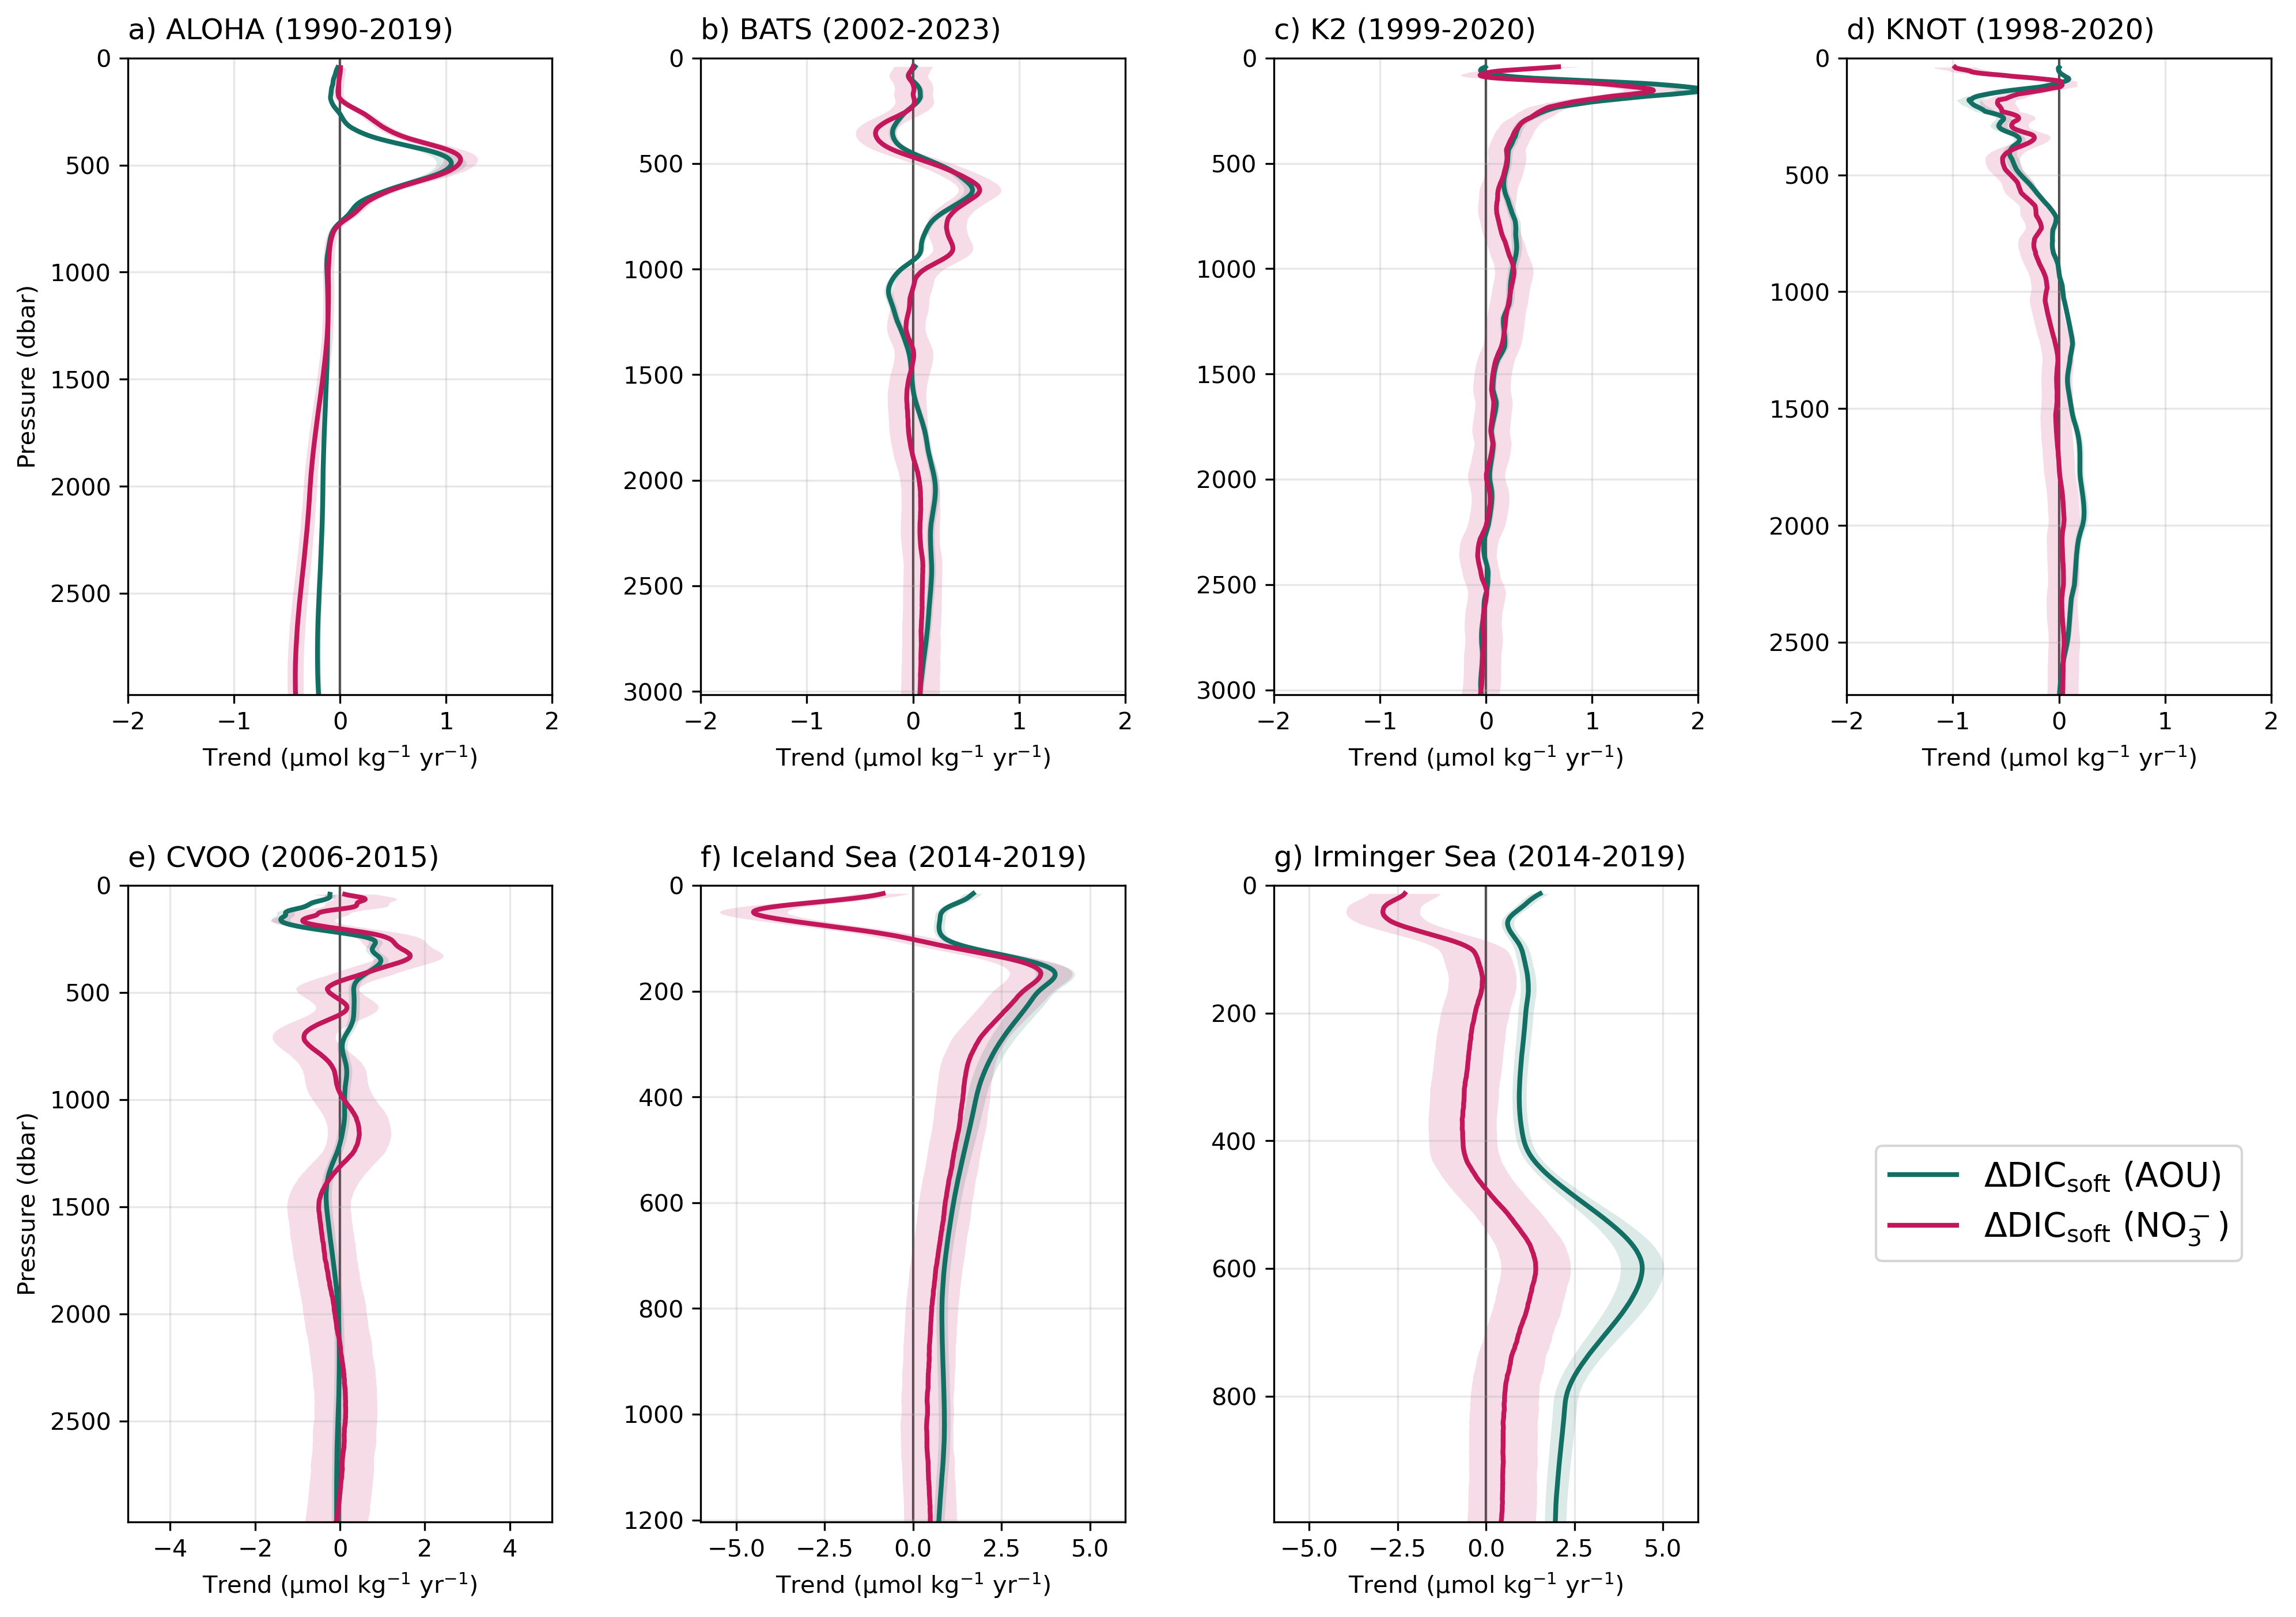

In [2]:
import subprocess
import sys
from IPython.display import Image, display

subprocess.run([sys.executable, "scripts/07_figS_nitrate_vs_aou.py"], cwd="ocean-time-series-bcp", check=True)
display(Image("figs/FigureS14.png", width=800))

**____________________________________________________________________________________________________________________________**


## Tables S1–S3

#### Relevant scripts: ocean-time-series-bcp/scripts/09_tableS1_station_periods.py (Table S1), 06_sequestration_depths.py (Table S2), 07_figS_nitrate_vs_aou.py (Table S3)

In [1]:
import pandas as pd
from IPython.display import display

PROC = "ocean-time-series-bcp/data/processed"
for title, f in [("Table S1", "tableS1_station_periods.csv"),
                 ("Table S2", "sequestration_depth_summary.csv"),
                 ("Table S3", "dicsoft_no3_aou_layer_trends.csv")]:
    print(title)
    display(pd.read_csv(f"{PROC}/{f}"))

Table S1


,Station,Time range,Period used in this study,Profiles
0,ALOHA,1988–2019,1990–2019,136
1,BATS,1988–2023,2002–2023,84
2,K2,1999–2020,1999–2020,28
3,KNOT,1992–2020,1998–2020,37
4,CVOO,2006–2019,2006–2015,5
5,Iceland Sea,1985–2019,2014–2019,19
6,Irminger Sea,1983–2019,2014–2019,14


Table S2


,Station,Slope (m/day),Slope (m/year),Slope Uncertainty (m/year),R²,P-value,Q1 Mean,Q1 Mean Uncertainty,Q4 Mean,Q4 Mean Uncertainty,Q Difference,Q Difference Uncertainty,T-stat,T-test P-value,Significance,Q4_mean_depth
0,ALOHA,-0.001389,-0.507486,0.019058,0.841053,2.283190e-55,1624.675681,0.499398,1611.394484,0.440627,-13.281197,0.665996,19.646409,4.875443e-29,S,1611.394484
1,BATS,0.004809,1.756409,0.306787,0.285575,1.644240e-07,1424.295217,1.482985,1448.784373,1.644034,24.489156,2.214066,-10.794152,2.328708e-13,S,1448.784373
2,K2,-0.002621,-0.957347,0.203933,0.458756,7.530327e-05,1443.997803,2.360699,1432.260545,2.049581,-11.737258,3.126289,3.475875,4.708954e-03,S,1432.260545
3,KNOT,0.002740,1.000934,0.146214,0.572459,6.048718e-08,1371.491122,0.606204,1382.815975,3.340137,11.324853,3.394702,-3.164843,1.059629e-02,S,1382.815975
4,CVOO,-0.004135,-1.510224,1.931547,0.169280,4.913227e-01,1112.473574,7.394893,1102.015616,6.338480,-10.457958,9.739649,0.759257,5.285868e-01,IS,1102.015616
5,IcelandSea,-0.015759,-5.755983,0.317450,0.950834,1.476614e-12,752.228376,1.427848,727.742998,0.152664,-24.485378,1.435986,15.251118,9.269976e-05,S,727.742998
6,IrmingerSea,-0.023383,-8.540498,1.273575,0.789361,2.177434e-05,769.595372,6.109692,739.297536,0.110252,-30.297836,6.110686,4.293903,2.319726e-02,S,739.297536


Table S3


,station,period,n_profiles,layer_dbar,DICsoft_AOU_change,DICsoft_AOU_error,DICsoft_NO3_change,DICsoft_NO3_error,residual_change,residual_error,residual_significant_1sigma
0,ALOHA,1990-2019,136,100-500,0.259,0.044,0.441,0.087,0.182,0.100,True
1,ALOHA,1990-2019,136,500-1000,0.194,0.040,0.223,0.071,0.029,0.083,False
2,ALOHA,1990-2019,136,1000-2000,-0.133,0.019,-0.176,0.056,-0.043,0.059,False
3,BATS,2002-2023,84,100-500,-0.043,0.033,-0.123,0.184,-0.080,0.187,False
4,BATS,2002-2023,84,500-1000,0.252,0.049,0.392,0.190,0.140,0.197,False
5,BATS,2002-2023,84,1000-2000,-0.017,0.034,-0.021,0.182,-0.005,0.185,False
6,K2,1999-2020,28,100-500,0.682,0.099,0.556,0.201,-0.127,0.230,False
7,K2,1999-2020,28,500-1000,0.237,0.043,0.157,0.178,-0.080,0.183,False
8,K2,1999-2020,28,1000-2000,0.123,0.034,0.114,0.177,-0.008,0.180,False
9,KNOT,1998-2020,37,100-500,-0.498,0.072,-0.397,0.159,0.101,0.175,False
